# Antibiotic-Group Scientific Interest in AMR

This notebook generalizes the yearly AMR scientific-interest workflow from individual antibiotics to a coarser antibiotic abstraction.

The user chooses one grouping column from `archive/legacy_assets/antibiotic_list2.xlsx`, for example:

- `Antibiotic`
- `Class`
- `Simplified categories`
- `High level categories`
- or any other column present in the spreadsheet

The workflow then:

1. maps each antibiotic to the chosen group
2. aggregates yearly AMR-positive counts from `(pathogen, antibiotic, year)` to `(pathogen, group, year)`
3. aggregates antibiotic background counts to the same group level
4. runs the same yearly SI modeling on `(pathogen, antibiotic_group, year)` pairs

Internally, the coarser group is renamed to the `antibiotic` column expected by the shared scientific-interest functions.


In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import Ridge

PROJECT_ROOT = None
for candidate in (Path.cwd(), *Path.cwd().parents):
    if (candidate / "amr").exists():
        PROJECT_ROOT = candidate
        break
    nested_candidate = candidate / "Antimicrobial Resistance"
    if (nested_candidate / "amr").exists():
        PROJECT_ROOT = nested_candidate
        break

if PROJECT_ROOT is None:
    raise ModuleNotFoundError("Could not locate the project root containing the 'amr' package.")

ARCHIVE_ROOT = PROJECT_ROOT / "archive"
if str(ARCHIVE_ROOT) not in sys.path:
    sys.path.insert(0, str(ARCHIVE_ROOT))

from amr_legacy.scientific_interest import (
    plot_yearly_si_pair,
    display_si_amr_pareto_front,
    plot_interactive_yearly_rank_shift,
    plot_yearly_si_prediction_for_pareto_pairs,
    plot_interactive_latest_observed_count_vs_future_si_shift,
    rank_yearly_pairs_by_future_si_shift,
    select_interesting_yearly_rank_cases,
)


## Configuration

Set `ANTIBIOTIC_GROUP_COLUMN` to any column present in `archive/legacy_assets/antibiotic_list2.xlsx`.
The selected grouping column becomes the coarse antibiotic dimension for all downstream analysis.


In [2]:
ARCHIVE_DIR = PROJECT_ROOT / "archive"
LEGACY_ASSETS_DIR = ARCHIVE_DIR / "legacy_assets"

ANTIBIOTIC_METADATA_PATH = LEGACY_ASSETS_DIR / "antibiotic_list2.xlsx"
REFINED_SCREEN_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined_screen.parquet"
REFINED_PAIR_PMID_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined_pair_pmid.parquet"
YEARLY_PATH = LEGACY_ASSETS_DIR / "pmids_results_positive_yearly_refined.parquet"
PATHOGEN_BG_PATH = PROJECT_ROOT / "pathogen_tiab_counts.parquet"
ANTIBIOTIC_BG_PATH = PROJECT_ROOT / "antibiotic_tiab_counts.parquet"

ANTIBIOTIC_GROUP_COLUMN = "Class"
N_ROWS = 30
SHOW_RANDOM_ROWS = True

RANK_FIT_START_YEAR = 1970
RANK_FIT_END_YEAR = 2020
RANK_NUM_FUTURE_YEARS = 5

RANK_OUTPUT_PATH = LEGACY_ASSETS_DIR / (
    f"si_yearly_rank_shift_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}_fit_{RANK_FIT_START_YEAR}_{RANK_FIT_END_YEAR}_ref_{RANK_FIT_END_YEAR}_future_{RANK_FIT_END_YEAR + RANK_NUM_FUTURE_YEARS}.parquet"
)
PARETO_PNG_DIR = LEGACY_ASSETS_DIR / f"pareto_pngs_yearly_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}"
INTERESTING_PNG_DIR = LEGACY_ASSETS_DIR / f"interesting_yearly_si_pngs_{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}"


In [3]:
antibiotics_df = pd.read_excel(ANTIBIOTIC_METADATA_PATH)
print("Available grouping columns:")
for col in antibiotics_df.columns:
    n_unique = pd.Series(antibiotics_df[col]).dropna().astype(str).nunique()
    print(f"- {col}: {n_unique}")

if ANTIBIOTIC_GROUP_COLUMN not in antibiotics_df.columns:
    raise KeyError(
        f"ANTIBIOTIC_GROUP_COLUMN={ANTIBIOTIC_GROUP_COLUMN!r} is not in antibiotic metadata columns {list(antibiotics_df.columns)}"
    )

sample_n = min(N_ROWS, len(antibiotics_df))
sample_df = antibiotics_df.sample(sample_n, random_state=None) if SHOW_RANDOM_ROWS else antibiotics_df.head(sample_n)
display(sample_df)


Available grouping columns:
- Antibiotic: 245
- Class: 39
- Simplified categories: 15
- High level categories: 11
- Origin: 2


,Antibiotic,Class,Simplified categories,High level categories,Origin
197,Rifampicin,Rifamycins,Rifamycins,Rifamycins,Naturally occurring/modified
38,Cefepime,Fourth-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
155,Clofoctol,Phenol derivatives,Miscellaneous,Other,Naturally occurring/modified
97,Carindacillin,Penicillins,Penicillins,Beta lactam and related,Naturally occurring/modified
196,Rifabutin,Rifamycins,Rifamycins,Rifamycins,Naturally occurring/modified
148,Dalfopristin/quinupristin,Streptogramins,Miscellaneous,MLS,Naturally occurring/modified
16,Tobramycin,Aminoglycosides,Aminocyclitols/Aminoglycosides,Aminocyclitols/Aminoglycosides,Naturally occurring/modified
46,Cefonicid,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
57,Cefpodoxime-proxetil,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified
73,Flomoxef,Second-generation-cephalosporins,Cephalosporins,Beta lactam and related,Naturally occurring/modified


## Build the antibiotic-to-group mapping

The mapping uses `Antibiotic` as the fine-grained source key and the user-selected column as the target group label.


In [4]:
if ANTIBIOTIC_GROUP_COLUMN == "Antibiotic":
    mapping_df = antibiotics_df[["Antibiotic"]].copy()
    mapping_df["antibiotic_group"] = mapping_df["Antibiotic"]
else:
    mapping_df = antibiotics_df[["Antibiotic", ANTIBIOTIC_GROUP_COLUMN]].copy()
    mapping_df = mapping_df.rename(columns={ANTIBIOTIC_GROUP_COLUMN: "antibiotic_group"})

mapping_df["Antibiotic"] = mapping_df["Antibiotic"].astype(str).str.strip()
mapping_df["antibiotic_group"] = mapping_df["antibiotic_group"].astype(str).str.strip()
mapping_df = mapping_df.replace({"": np.nan}).dropna(subset=["Antibiotic", "antibiotic_group"])

duplicate_mapping_df = (
    mapping_df.groupby("Antibiotic")["antibiotic_group"]
    .nunique()
    .reset_index(name="n_groups")
)
duplicate_mapping_df = duplicate_mapping_df.loc[duplicate_mapping_df["n_groups"] > 1]
if not duplicate_mapping_df.empty:
    raise ValueError(
        f"Some antibiotics map to multiple {ANTIBIOTIC_GROUP_COLUMN!r} values. Fix the metadata first."
    )

mapping_df = mapping_df.drop_duplicates(subset=["Antibiotic"]).reset_index(drop=True)
print(f"Mapped {len(mapping_df):,} antibiotics into {mapping_df['antibiotic_group'].nunique():,} groups using column {ANTIBIOTIC_GROUP_COLUMN!r}.")
display(mapping_df.sample(min(N_ROWS, len(mapping_df)), random_state=None))


Mapped 245 antibiotics into 38 groups using column 'Class'.


,Antibiotic,antibiotic_group
93,Bacampicillin,Penicillins
177,Levonadifloxacin,Fluoroquinolones
90,Aspoxicillin,Penicillins
117,Propicillin,Penicillins
66,Ceftezole,First-generation-cephalosporins
89,Ampicillin,Penicillins
40,Cefiderocol,Other-cephalosporins
110,Penamecillin,Penicillins
151,Furazidin,Nitrofuran derivatives
145,Telithromycin,Macrolides


## Load yearly AMR counts and yearly backgrounds at the chosen group level

This cell remaps yearly AMR-positive rows and antibiotic background counts from individual antibiotics to the selected coarse grouping.


In [5]:
yearly_df_raw = pd.read_parquet(YEARLY_PATH)
pathogen_bg_df = pd.read_parquet(PATHOGEN_BG_PATH).rename(columns={"count": "bg_pathogen_n"})
antibiotic_bg_df_raw = pd.read_parquet(ANTIBIOTIC_BG_PATH)

yearly_df_grouped = (
    yearly_df_raw.merge(mapping_df, left_on="antibiotic", right_on="Antibiotic", how="left")
)
amr_mapping_coverage = yearly_df_grouped["antibiotic_group"].notna().mean()
print(f"AMR yearly mapping coverage: {100 * amr_mapping_coverage:.2f}%")

yearly_df_grouped = yearly_df_grouped.dropna(subset=["antibiotic_group"]).copy()
yearly_df_grouped["pmids"] = yearly_df_grouped["pmids"].apply(lambda x: x if isinstance(x, list) else [])
yearly_df_grouped = (
    yearly_df_grouped.groupby(["pathogen", "antibiotic_group", "year"], as_index=False)
    .agg(
        count=("count", "sum"),
        pmids=("pmids", lambda lists: list(dict.fromkeys(pmid for sub in lists for pmid in sub))),
    )
)

antibiotic_bg_df = antibiotic_bg_df_raw.merge(mapping_df, left_on="antibiotic", right_on="Antibiotic", how="left")
bg_mapping_coverage = antibiotic_bg_df["antibiotic_group"].notna().mean()
print(f"Antibiotic background mapping coverage: {100 * bg_mapping_coverage:.2f}%")

antibiotic_bg_df = antibiotic_bg_df.dropna(subset=["antibiotic_group"]).copy()
antibiotic_bg_df = (
    antibiotic_bg_df.groupby(["antibiotic_group", "year"], as_index=False)["count"]
    .sum()
    .rename(columns={"count": "bg_antibiotic_n"})
)

amr_yearly_df = (
    yearly_df_grouped.merge(pathogen_bg_df, on=["pathogen", "year"], how="left")
    .merge(antibiotic_bg_df, on=["antibiotic_group", "year"], how="left")
    .rename(columns={"antibiotic_group": "antibiotic"})
    .copy()
)

amr_yearly_df["count"] = pd.to_numeric(amr_yearly_df["count"], errors="coerce")
amr_yearly_df["bg_pathogen_n"] = pd.to_numeric(amr_yearly_df["bg_pathogen_n"], errors="coerce")
amr_yearly_df["bg_antibiotic_n"] = pd.to_numeric(amr_yearly_df["bg_antibiotic_n"], errors="coerce")
amr_yearly_df["log_count"] = np.log10(1 + amr_yearly_df["count"])
amr_yearly_df["log_bg_pathogen_n"] = np.log10(1 + amr_yearly_df["bg_pathogen_n"])
amr_yearly_df["log_bg_antibiotic_n"] = np.log10(1 + amr_yearly_df["bg_antibiotic_n"])
amr_yearly_df = amr_yearly_df.dropna(
    subset=["count", "bg_pathogen_n", "bg_antibiotic_n", "log_count", "log_bg_pathogen_n", "log_bg_antibiotic_n"]
).reset_index(drop=True)

print(f"grouped yearly AMR rows: {len(amr_yearly_df):,}")
print(f"unique pathogen-{ANTIBIOTIC_GROUP_COLUMN.lower()} pairs: {amr_yearly_df[['pathogen', 'antibiotic']].drop_duplicates().shape[0]:,}")
print(f"unique {ANTIBIOTIC_GROUP_COLUMN.lower()} values in modeled data: {amr_yearly_df['antibiotic'].nunique():,}")
print(f"year span: {int(amr_yearly_df['year'].min())} to {int(amr_yearly_df['year'].max())}")


AMR yearly mapping coverage: 96.82%
Antibiotic background mapping coverage: 98.79%
grouped yearly AMR rows: 27,075
unique pathogen-class pairs: 5,023
unique class values in modeled data: 38
year span: 1975 to 2025


In [6]:
sample_n = min(N_ROWS, len(amr_yearly_df))
sample_df = amr_yearly_df.sample(sample_n, random_state=None) if SHOW_RANDOM_ROWS else amr_yearly_df.head(sample_n)
display(sample_df)


,pathogen,antibiotic,year,count,pmids,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n
6026,Edwardsiella tarda,Tetracyclines,1977,1,[],6.0,533,0.301030,0.845098,2.727541
14828,Neisseria gonorrhoeae,Aminocyclitols,2020,1,[],431.0,55,0.301030,2.635484,1.748188
971,Acinetobacter seifertii,Beta-lactam/beta-lactamase-inhibitor_anti-pseu...,2024,1,[],3.0,587,0.301030,0.602060,2.769377
24842,Streptococcus pneumoniae,Macrolides,2019,44,[],1027.0,2092,1.653213,3.011993,3.320769
19744,Shigella dysenteriae,Penicillins,2014,1,[],38.0,2481,0.301030,1.591065,3.394802
8871,Escherichia coli,Carbapenems,2021,73,[],11117.0,1425,1.869232,4.046027,3.154120
24869,Streptococcus pneumoniae,Penicillins,1989,4,[],263.0,1313,0.698970,2.421604,3.118595
367,Acinetobacter baumannii,Fourth-generation-cephalosporins,2011,5,[],503.0,171,0.778151,2.702431,2.235528
17072,Providencia stuartii,Aminoglycosides,1983,1,[],9.0,1468,0.301030,1.000000,3.167022
15142,Neisseria gonorrhoeae,Trimethoprim-derivatives,1997,2,[],183.0,266,0.477121,2.264818,2.426511


## Trajectory density of pathogen-group pairs

Before fitting the pooled SI model, it is useful to inspect how many yearly observations are available for each pathogen-group pair. This helps quantify how dense or sparse the grouped trajectories are and provides a figure that can be reused in the proposal.

{'min_avg_count': 2.0, 'total_pairs_before_filter': 5023, 'total_pairs_after_filter': 676, 'median_years_per_pair': 17.0, 'mean_years_per_pair': 18.15680473372781, 'min_years_per_pair': 1, 'max_years_per_pair': 50, 'pairs_ge_2_years': 513, 'pairs_ge_3_years': 475, 'pairs_ge_5_years': 445, 'pairs_ge_10_years': 398, 'pairs_ge_20_years': 307}


,pathogen,antibiotic,n_years,total_count,mean_yearly_count
1890,Escherichia coli,Penicillins,50,4473,89.460000
1877,Escherichia coli,Fluoroquinolones,38,2897,76.236842
4040,Staphylococcus aureus,Penicillins,50,3509,70.180000
1901,Escherichia coli,Third-generation-cephalosporins,43,2732,63.534884
1781,Enterococcus faecium,Glycopeptides,37,2163,58.459459
2175,Helicobacter pylori,Macrolides,32,1778,55.562500
2322,Klebsiella pneumoniae,Polymyxins,19,1019,53.631579
1869,Escherichia coli,Aminoglycosides,50,2605,52.100000
1892,Escherichia coli,Polymyxins,24,1241,51.708333
2945,Mycobacterium tuberculosis,Rifamycins,46,2189,47.586957


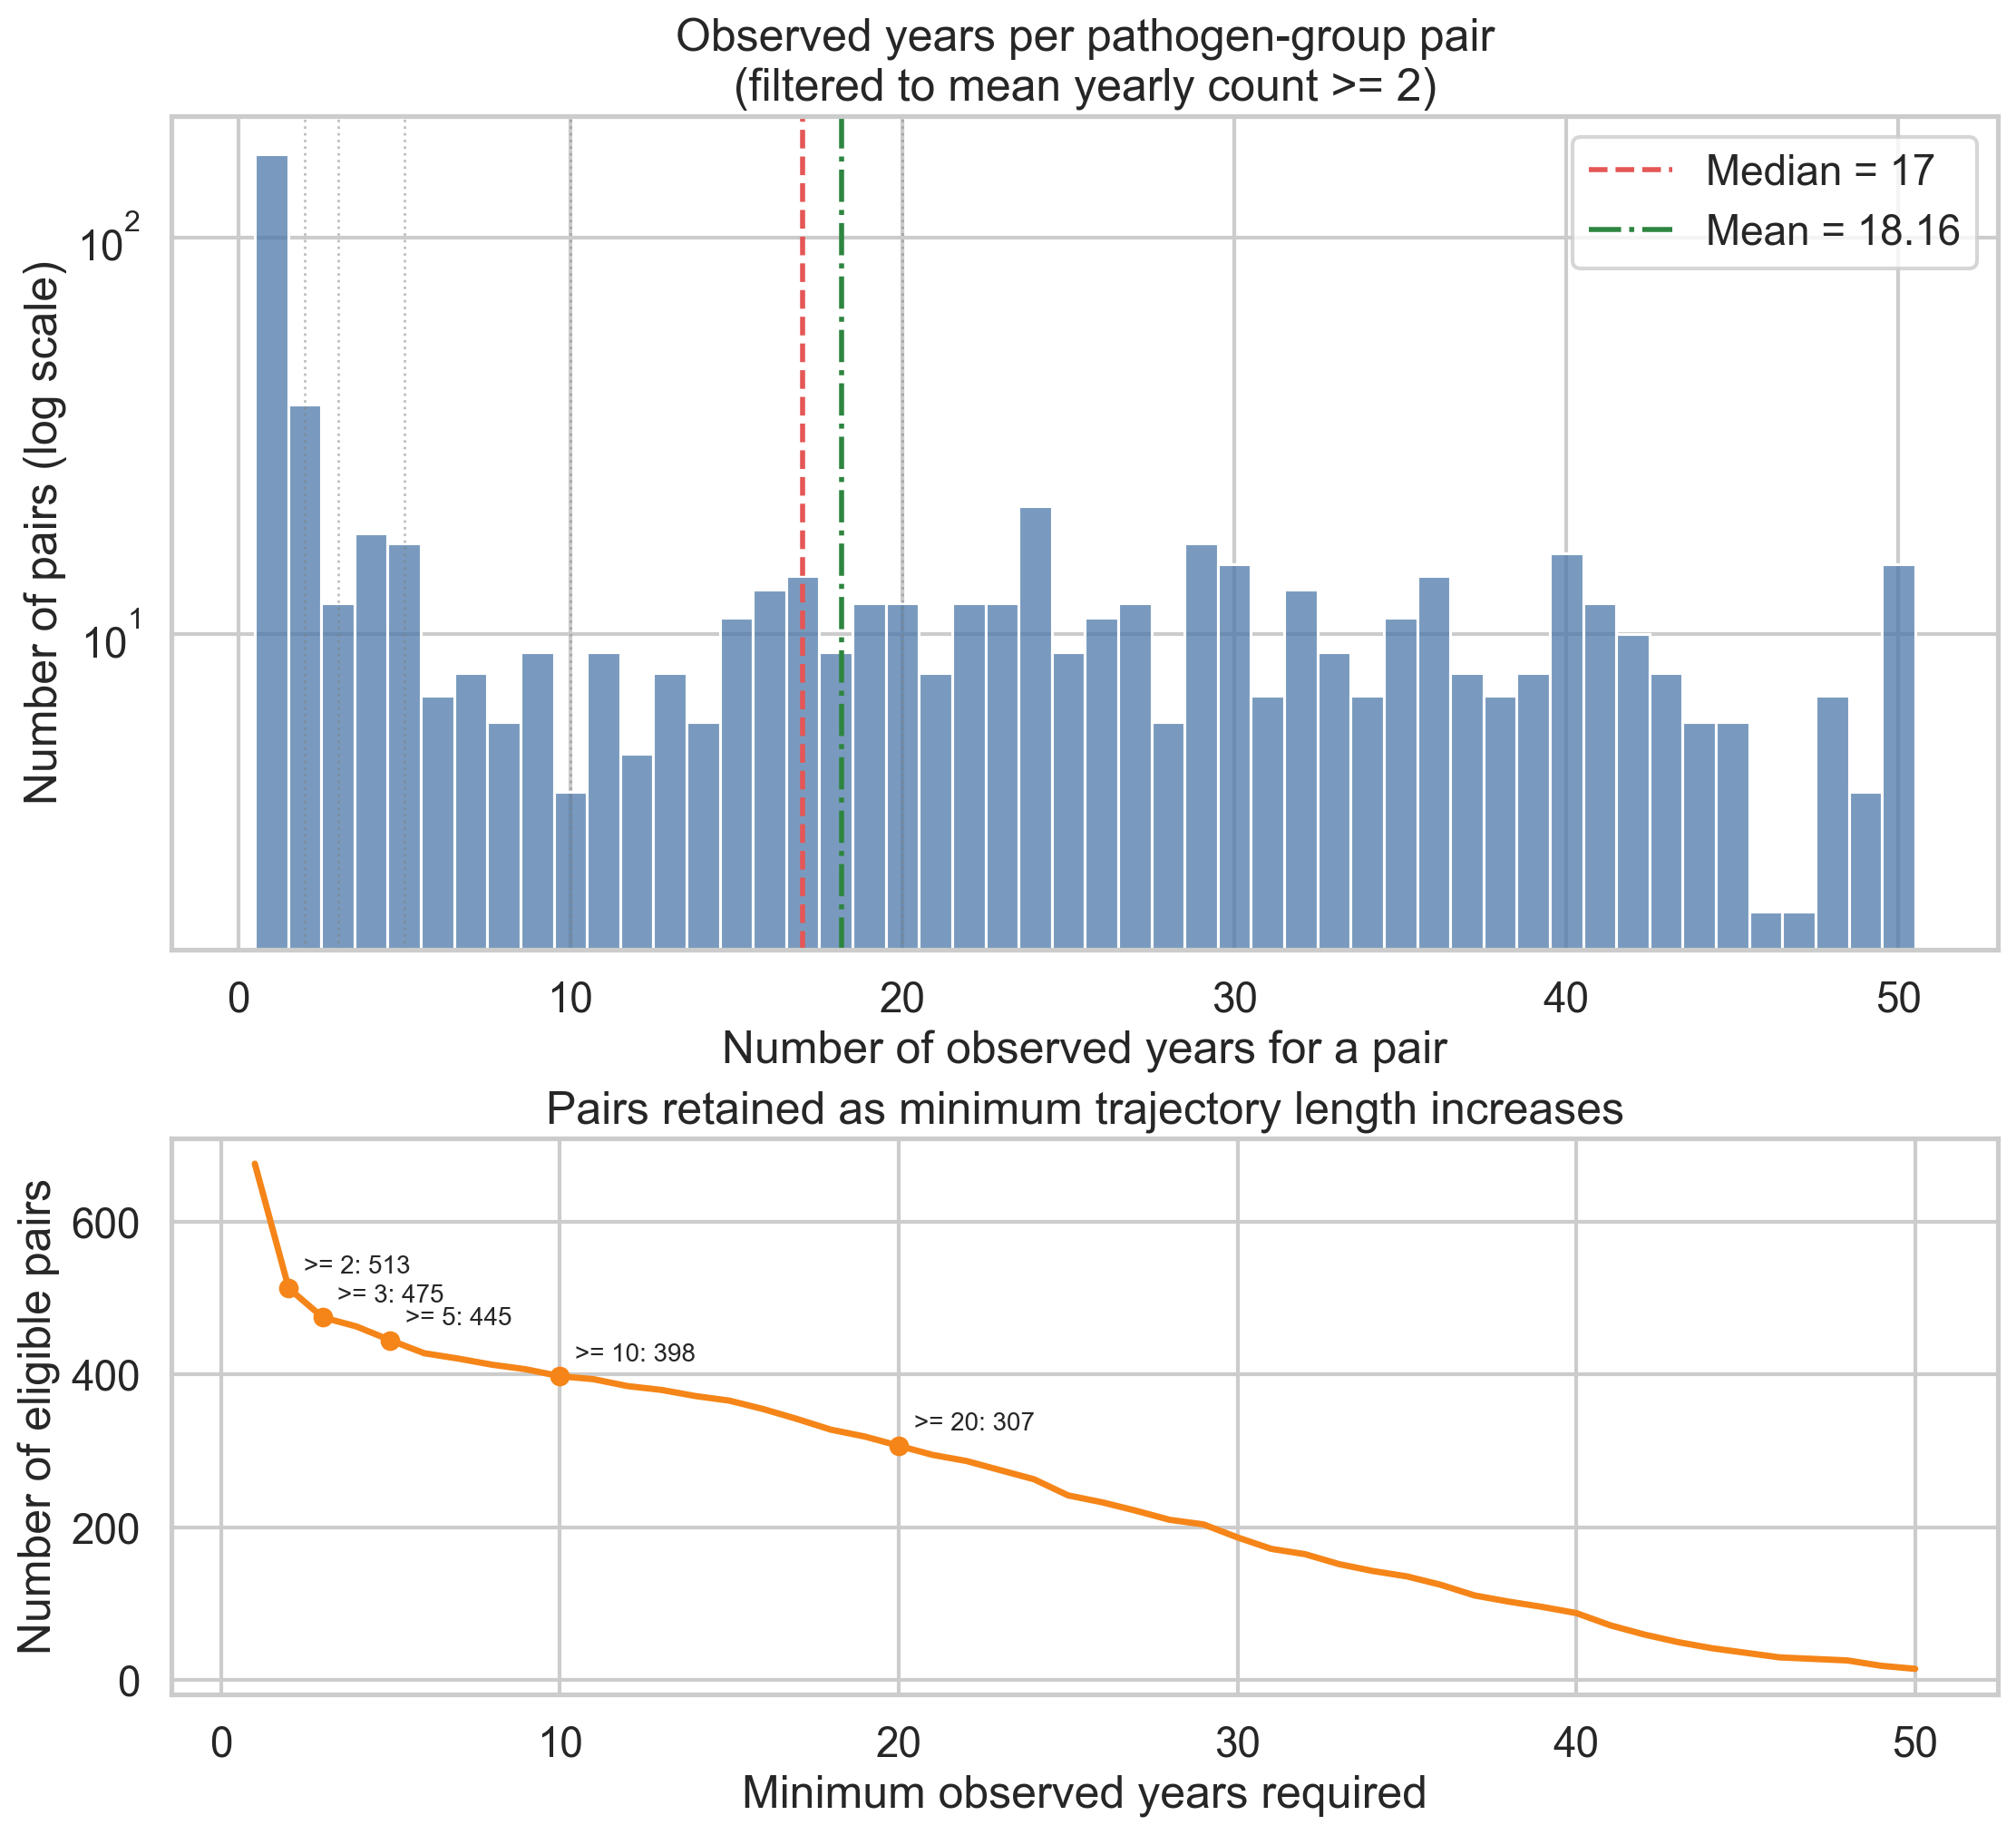

Saved trajectory histogram to /Users/fabriziocosta/Resilio Sync/Sync/Projects/Pathogen Atlas/Antimicrobial Resistance/archive/legacy_assets/class_pair_trajectory_histogram_min_avg_count_2.png


In [7]:
MIN_AVG_COUNT = 2
TRAJECTORY_HIST_PATH = LEGACY_ASSETS_DIR / f"{ANTIBIOTIC_GROUP_COLUMN.lower().replace(' ', '_')}_pair_trajectory_histogram_min_avg_count_{MIN_AVG_COUNT}.png"

pair_summary_df = (
    amr_yearly_df.groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        n_years=("year", "nunique"),
        total_count=("count", "sum"),
        mean_yearly_count=("count", "mean"),
    )
)

filtered_pair_df = pair_summary_df.loc[pair_summary_df["mean_yearly_count"] >= float(MIN_AVG_COUNT)].copy()
if filtered_pair_df.empty:
    raise ValueError(f"No pathogen-group pairs remain after applying MIN_AVG_COUNT={MIN_AVG_COUNT}.")

summary = {
    "min_avg_count": float(MIN_AVG_COUNT),
    "total_pairs_before_filter": int(len(pair_summary_df)),
    "total_pairs_after_filter": int(len(filtered_pair_df)),
    "median_years_per_pair": float(filtered_pair_df["n_years"].median()),
    "mean_years_per_pair": float(filtered_pair_df["n_years"].mean()),
    "min_years_per_pair": int(filtered_pair_df["n_years"].min()),
    "max_years_per_pair": int(filtered_pair_df["n_years"].max()),
    "pairs_ge_2_years": int((filtered_pair_df["n_years"] >= 2).sum()),
    "pairs_ge_3_years": int((filtered_pair_df["n_years"] >= 3).sum()),
    "pairs_ge_5_years": int((filtered_pair_df["n_years"] >= 5).sum()),
    "pairs_ge_10_years": int((filtered_pair_df["n_years"] >= 10).sum()),
    "pairs_ge_20_years": int((filtered_pair_df["n_years"] >= 20).sum()),
}
print(summary)

display(
    filtered_pair_df.sort_values(["mean_yearly_count", "n_years"], ascending=False).head(min(N_ROWS, len(filtered_pair_df)))
)

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="talk")
fig, axes = plt.subplots(
    2,
    1,
    figsize=(11, 10),
    gridspec_kw={"height_ratios": [3, 2]},
    constrained_layout=True,
)

bins = np.arange(0.5, filtered_pair_df["n_years"].max() + 1.5, 1)

ax = axes[0]
sns.histplot(
    filtered_pair_df,
    x="n_years",
    bins=bins,
    discrete=True,
    color="#4C78A8",
    edgecolor="white",
    ax=ax,
)
ax.axvline(
    filtered_pair_df["n_years"].median(),
    color="#E45756",
    linestyle="--",
    linewidth=2,
    label=f"Median = {filtered_pair_df['n_years'].median():.0f}",
)
ax.axvline(
    filtered_pair_df["n_years"].mean(),
    color="#2E8540",
    linestyle="-.",
    linewidth=2,
    label=f"Mean = {filtered_pair_df['n_years'].mean():.2f}",
)
for threshold in [2, 3, 5, 10, 20]:
    ax.axvline(threshold, color="gray", linestyle=":", linewidth=1, alpha=0.5)
ax.set_title(
    f"Observed years per pathogen-group pair\n(filtered to mean yearly count >= {MIN_AVG_COUNT:g})"
)
ax.set_xlabel("Number of observed years for a pair")
ax.set_ylabel("Number of pairs (log scale)")
ax.set_yscale("log")
ax.legend(frameon=True)

ax2 = axes[1]
thresholds = np.arange(1, filtered_pair_df["n_years"].max() + 1)
eligible_pairs = np.array([(filtered_pair_df["n_years"] >= k).sum() for k in thresholds])
ax2.plot(thresholds, eligible_pairs, color="#F58518", linewidth=2.5)
for threshold in [2, 3, 5, 10, 20]:
    if threshold <= thresholds.max():
        count = int((filtered_pair_df["n_years"] >= threshold).sum())
        ax2.scatter([threshold], [count], color="#F58518", s=40)
        ax2.annotate(f">= {threshold}: {count:,}", (threshold, count), textcoords="offset points", xytext=(6, 6), fontsize=10)
ax2.set_title("Pairs retained as minimum trajectory length increases")
ax2.set_xlabel("Minimum observed years required")
ax2.set_ylabel("Number of eligible pairs")

fig.savefig(TRAJECTORY_HIST_PATH, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved trajectory histogram to {TRAJECTORY_HIST_PATH}")

## Pooled yearly baseline model at the group level

The model is unchanged except that the antibiotic dimension is now the selected coarse grouping.


In [8]:
alpha = 1.0

pathogen_dummies = pd.get_dummies(amr_yearly_df["pathogen"].astype(str), prefix="pathogen", dtype=float)
antibiotic_dummies = pd.get_dummies(amr_yearly_df["antibiotic"].astype(str), prefix="antibiotic", dtype=float)

design_df = pd.concat(
    [
        amr_yearly_df[["log_bg_pathogen_n", "log_bg_antibiotic_n"]].reset_index(drop=True),
        pathogen_dummies.reset_index(drop=True),
        antibiotic_dummies.reset_index(drop=True),
    ],
    axis=1,
)

response = amr_yearly_df["log_count"].to_numpy(dtype=float)
pooled_model = Ridge(alpha=alpha, fit_intercept=True)
pooled_model.fit(design_df, response)

si_df = amr_yearly_df.copy()
si_df["expected_log_count_global"] = pooled_model.predict(design_df)
si_df["expected_count_global"] = np.clip(np.power(10.0, si_df["expected_log_count_global"]) - 1.0, 0.0, None)
si_df["SI"] = si_df["log_count"] - si_df["expected_log_count_global"]

display(
    si_df[
        [
            "pathogen",
            "antibiotic",
            "year",
            "count",
            "bg_pathogen_n",
            "bg_antibiotic_n",
            "expected_count_global",
            "SI",
        ]
    ].head(N_ROWS)
)


,pathogen,antibiotic,year,count,bg_pathogen_n,bg_antibiotic_n,expected_count_global,SI
0,Abiotrophia defectiva,Fluoroquinolones,2013,1,4.0,2610,1.359556,-0.071800
1,Abiotrophia defectiva,Fluoroquinolones,2015,1,6.0,2765,1.555705,-0.106481
2,Abiotrophia defectiva,Fourth-generation-cephalosporins,2016,1,17.0,210,0.614514,0.092988
3,Abiotrophia defectiva,Lincosamides,2000,1,7.0,213,0.651957,0.083031
4,Abiotrophia defectiva,Lincosamides,2015,1,6.0,550,0.890641,0.024421
5,Abiotrophia defectiva,Lipopeptides,2021,1,14.0,253,0.972351,0.006046
6,Abiotrophia defectiva,Macrolides,2000,1,7.0,1328,1.316338,-0.063772
7,Abiotrophia defectiva,Macrolides,2015,1,6.0,1782,1.369766,-0.073676
8,Abiotrophia defectiva,Rifamycins,2013,1,4.0,867,0.420899,0.148467
9,Abiotrophia defectiva,Tetracyclines,2000,2,7.0,1140,1.053177,0.164695


In [9]:
coef_df = pd.DataFrame({"feature": design_df.columns, "coefficient": pooled_model.coef_})
display(coef_df[coef_df["feature"].isin(["log_bg_pathogen_n", "log_bg_antibiotic_n"])])
print("Model intercept:", float(pooled_model.intercept_))


,feature,coefficient
0,log_bg_pathogen_n,0.207843
1,log_bg_antibiotic_n,0.172041


Model intercept: -0.46252848816496206


## Rank pathogen-group pairs by average yearly scientific interest


In [10]:
pair_summary_df = (
    si_df.groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        mean_SI=("SI", "mean"),
        total_count=("count", "sum"),
        mean_count=("count", "mean"),
        n_years=("year", "nunique"),
        first_year=("year", "min"),
        last_year=("year", "max"),
    )
    .sort_values(["mean_SI", "total_count"], ascending=[False, False])
    .reset_index(drop=True)
)

display(pair_summary_df.head(20))


,pathogen,antibiotic,mean_SI,total_count,mean_count,n_years,first_year,last_year
0,Lactococcus lactis,Sulfonamides,0.920880,1,1.000000,1,1985,1985
1,Enterococcus faecium,Glycopeptides,0.864656,2163,58.459459,37,1988,2024
2,Haemophilus influenzae,Penicillins,0.634571,1204,24.080000,50,1975,2024
3,Staphylococcus warneri,Sulfonamides,0.618892,1,1.000000,1,1980,1980
4,Staphylococcus hominis,Sulfonamides,0.594168,1,1.000000,1,1980,1980
5,Mycobacterium tuberculosis,Rifamycins,0.592184,2189,47.586957,46,1975,2025
6,Helicobacter pylori,Macrolides,0.580454,1778,55.562500,32,1993,2024
7,Enterococcus faecalis,Glycopeptides,0.557352,882,23.837838,37,1988,2024
8,Staphylococcus aureus,Penicillins,0.553338,3509,70.180000,50,1975,2024
9,Streptococcus equi,Sulfonamides,0.548005,1,1.000000,1,1999,1999


## Plot one yearly pathogen-group trajectory

Choose any pathogen and any coarse antibiotic group present in `si_df`.


Random eligible pair: Salmonella enterica vs Sulfonamide-trimethoprim-combinations (n_train_years=37, total_count=205)


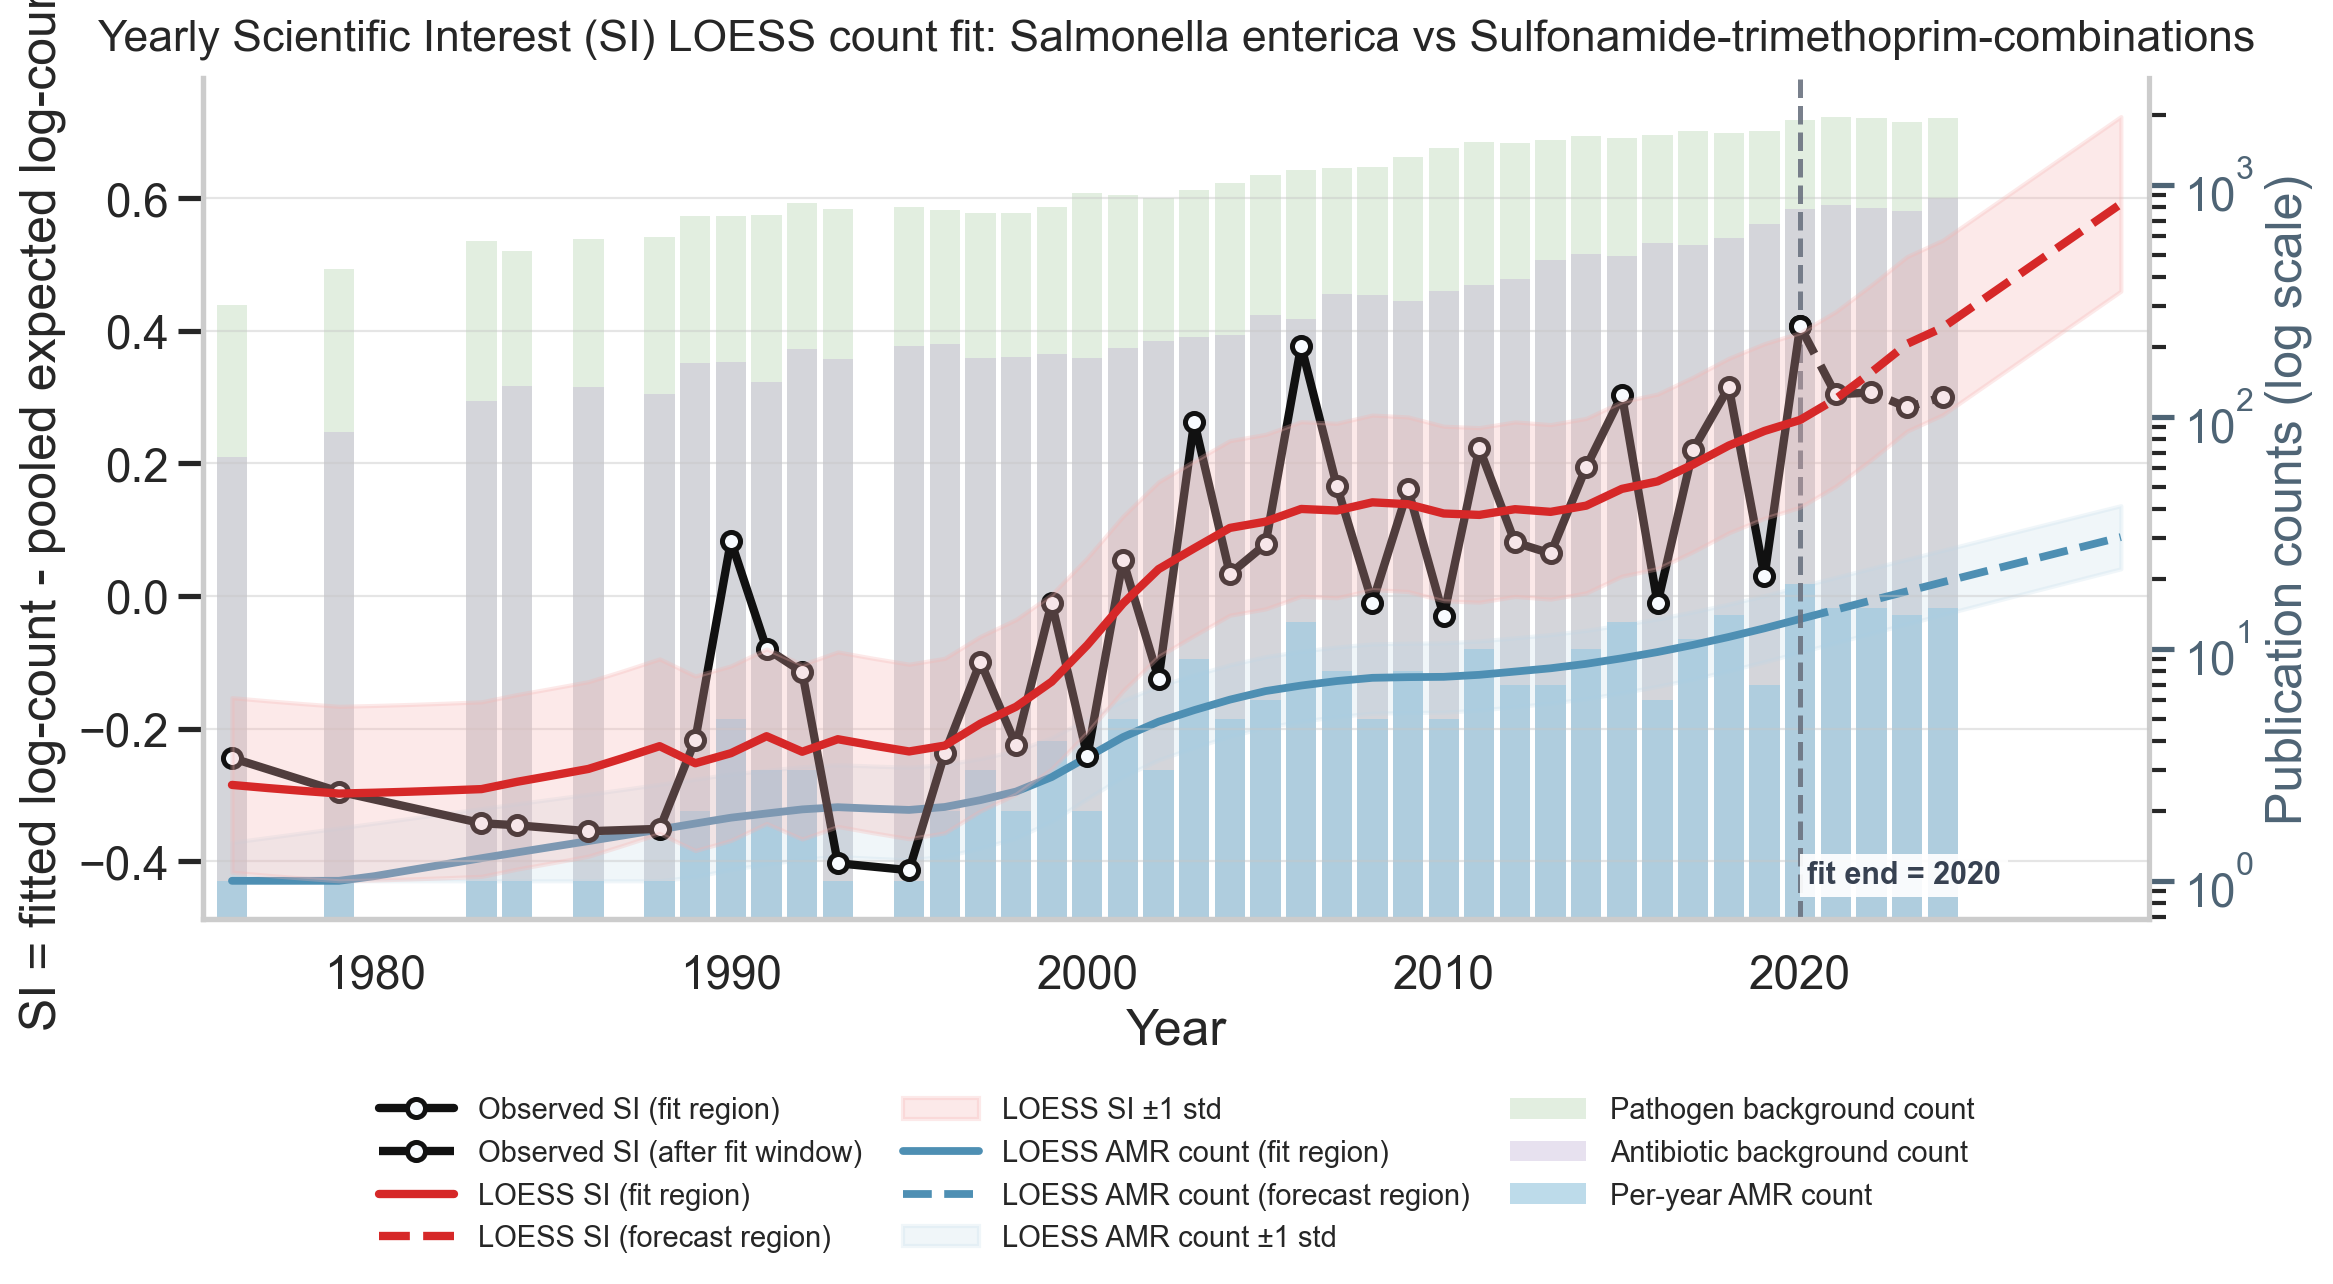

Example plot for Salmonella enterica vs Sulfonamide-trimethoprim-combinations (Class)
Observed vs predicted yearly AMR counts


,year,observed_count,predicted_count,diff,pct_error
0,1976,1,1,0,0.000000
1,1979,1,1,0,0.000000
2,1983,1,1,0,0.000000
3,1984,1,1,0,0.000000
4,1986,1,1,0,0.000000
5,1988,1,2,-1,-100.000000
6,1989,2,2,0,0.000000
7,1990,5,2,3,60.000000
8,1991,3,2,1,33.333333
9,1992,3,2,1,33.333333


LOESS fraction: 0.6
LOESS degree: 2
Training residual std on log-count scale: 0.1315968467372174
Latest observed year: 2024


In [11]:
MIN_TRAIN_YEARS = 10
MIN_TOTAL_AMR_COUNT = 200

eligible_pairs = (
    si_df.loc[si_df["year"].between(RANK_FIT_START_YEAR, RANK_FIT_END_YEAR)]
    .groupby(["pathogen", "antibiotic"], as_index=False)
    .agg(
        n_train_years=("year", "nunique"),
        total_count=("count", "sum"),
    )
    .query("n_train_years >= @MIN_TRAIN_YEARS and total_count >= @MIN_TOTAL_AMR_COUNT")
    .reset_index(drop=True)
)

if eligible_pairs.empty:
    raise ValueError(
        f"No pathogen-group pairs have at least {MIN_TRAIN_YEARS} training years "
        f"and total AMR count >= {MIN_TOTAL_AMR_COUNT}."
    )

example_row = eligible_pairs.sample(1, random_state=None).iloc[0]
example_pathogen = example_row["pathogen"]
example_group = example_row["antibiotic"]

print(
    f"Random eligible pair: {example_pathogen} vs {example_group} "
    f"(n_train_years={example_row['n_train_years']}, total_count={example_row['total_count']})"
)


result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen=example_pathogen,
    antibiotic=example_group,
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_additional_years=RANK_NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
)

print(f"Example plot for {example_pathogen} vs {example_group} ({ANTIBIOTIC_GROUP_COLUMN})")
print("Observed vs predicted yearly AMR counts")
display(result["comparison_df"])
print("LOESS fraction:", result["loess_fit"]["frac"])
print("LOESS degree:", result["loess_fit"]["degree"])
print("Training residual std on log-count scale:", result["loess_fit"]["residual_std"])
print("Latest observed year:", result["latest_available_year"])


## Pareto-front examples at the group level


,pareto_shell,pathogen,antibiotic,mean_SI,mean_count,total_count,n_intervals,n_years,latest_year
0,1,Lactococcus lactis,Sulfonamides,0.920880,1.000000,1,1,1,1985
1,1,Enterococcus faecium,Glycopeptides,0.864656,58.459459,2163,37,37,2024
2,1,Staphylococcus aureus,Penicillins,0.553338,70.180000,3509,50,50,2024
3,1,Escherichia coli,Penicillins,0.547311,89.460000,4473,50,50,2024
4,2,Haemophilus influenzae,Penicillins,0.634571,24.080000,1204,50,50,2024
5,2,Mycobacterium tuberculosis,Rifamycins,0.592184,47.586957,2189,46,46,2025
6,2,Helicobacter pylori,Macrolides,0.580454,55.562500,1778,32,32,2024
7,2,Escherichia coli,Fluoroquinolones,0.399778,76.236842,2897,38,38,2024
8,3,Staphylococcus warneri,Sulfonamides,0.618892,1.000000,1,1,1,1980
9,3,Enterococcus faecalis,Glycopeptides,0.557352,23.837838,882,37,37,2024


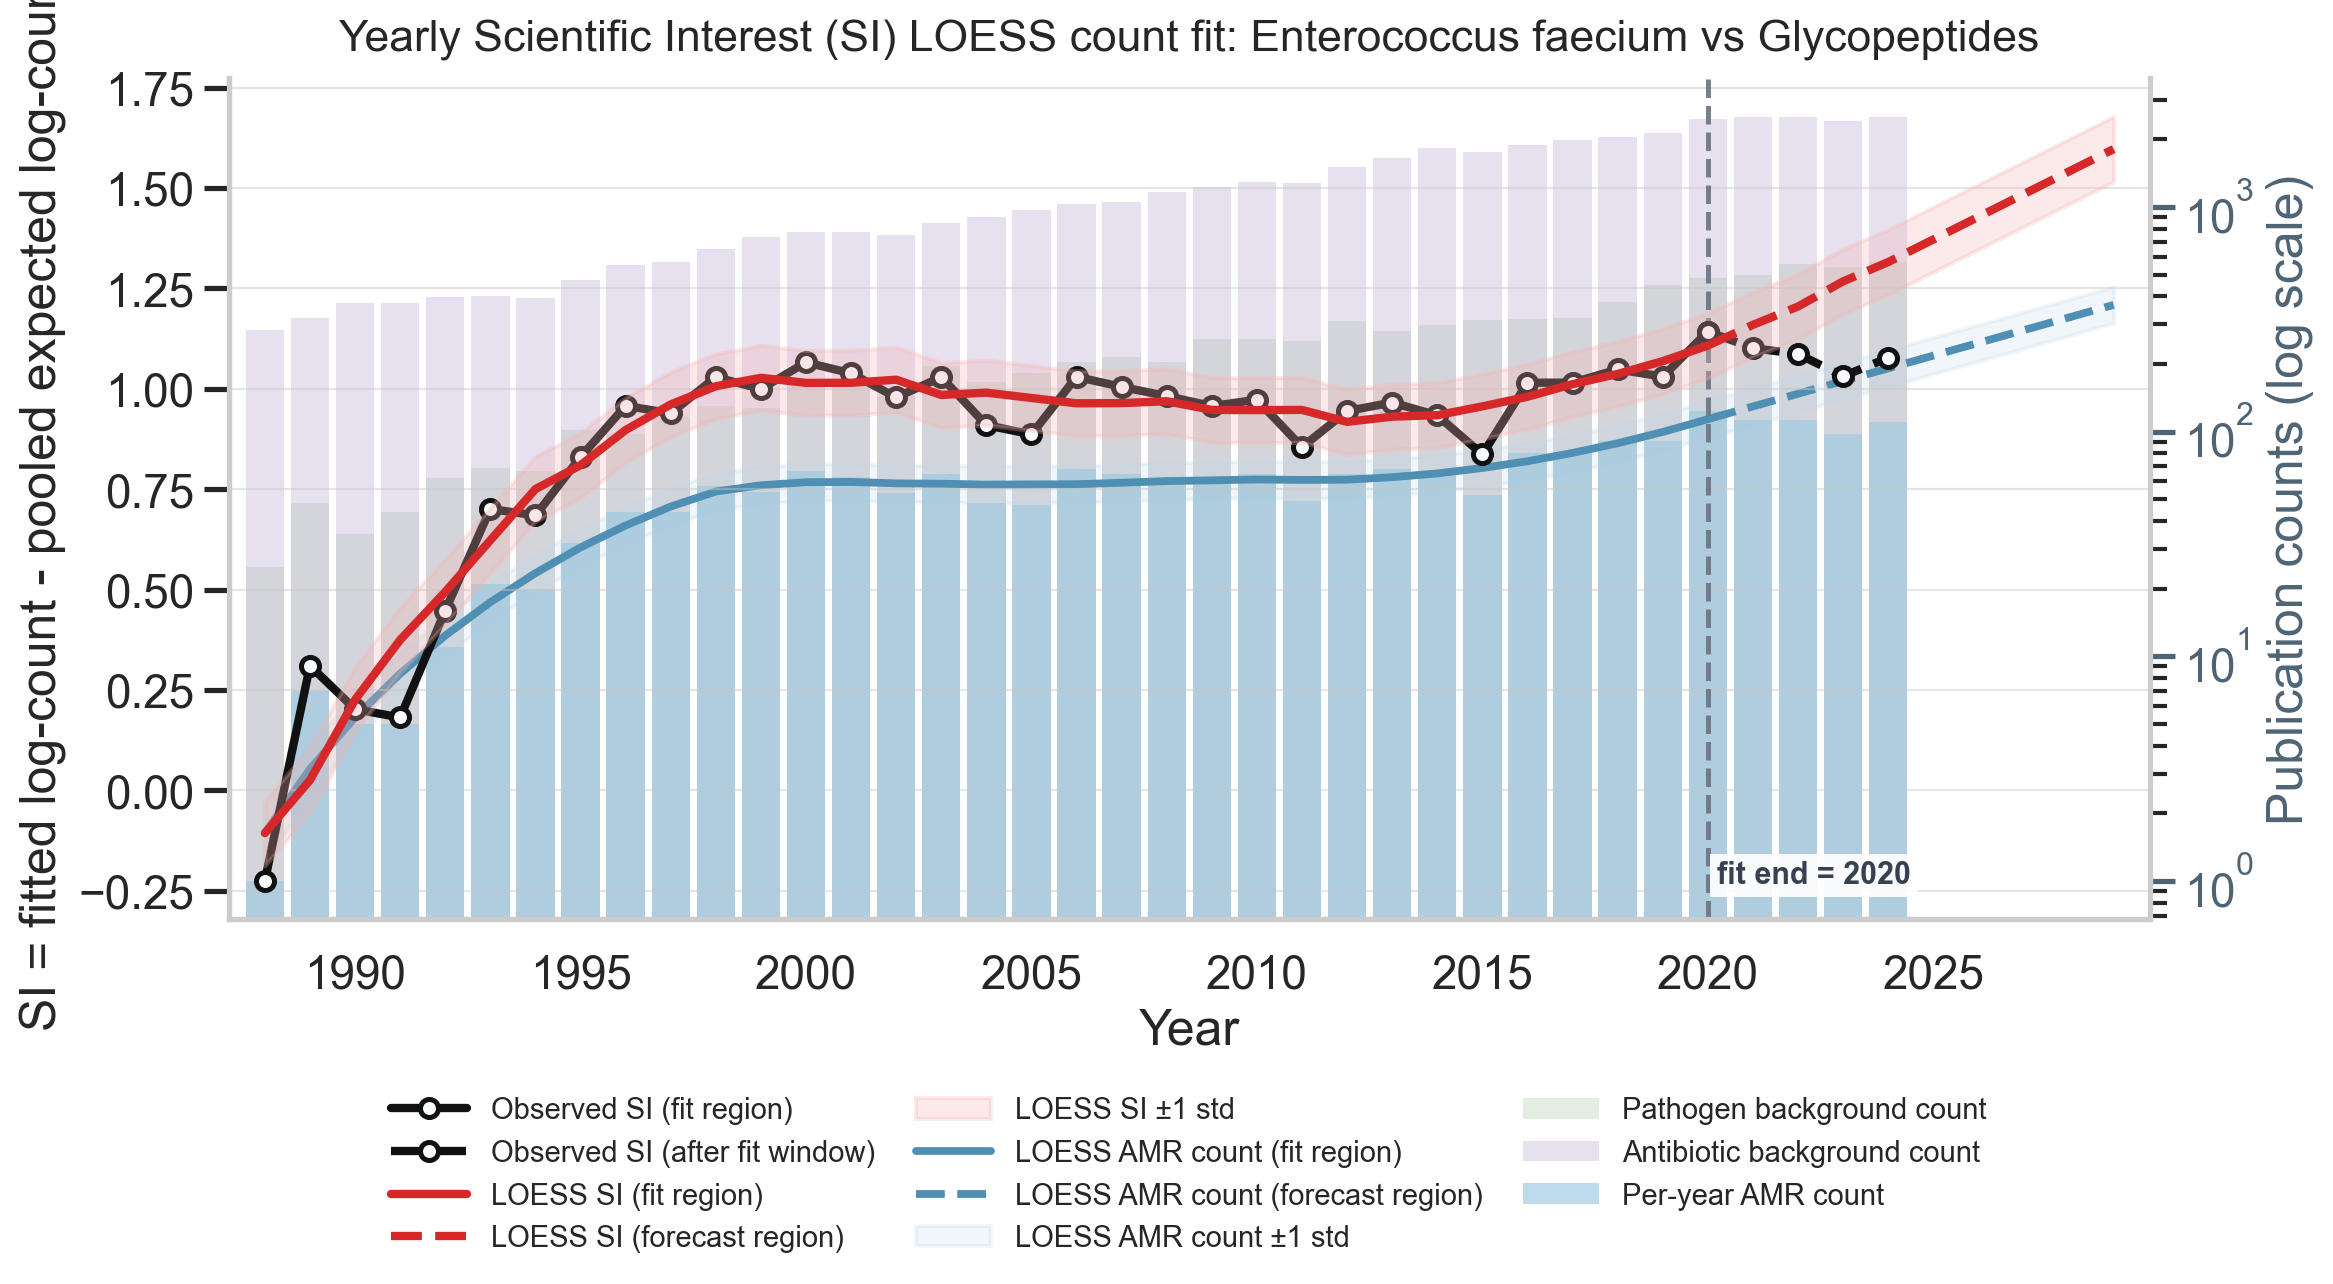

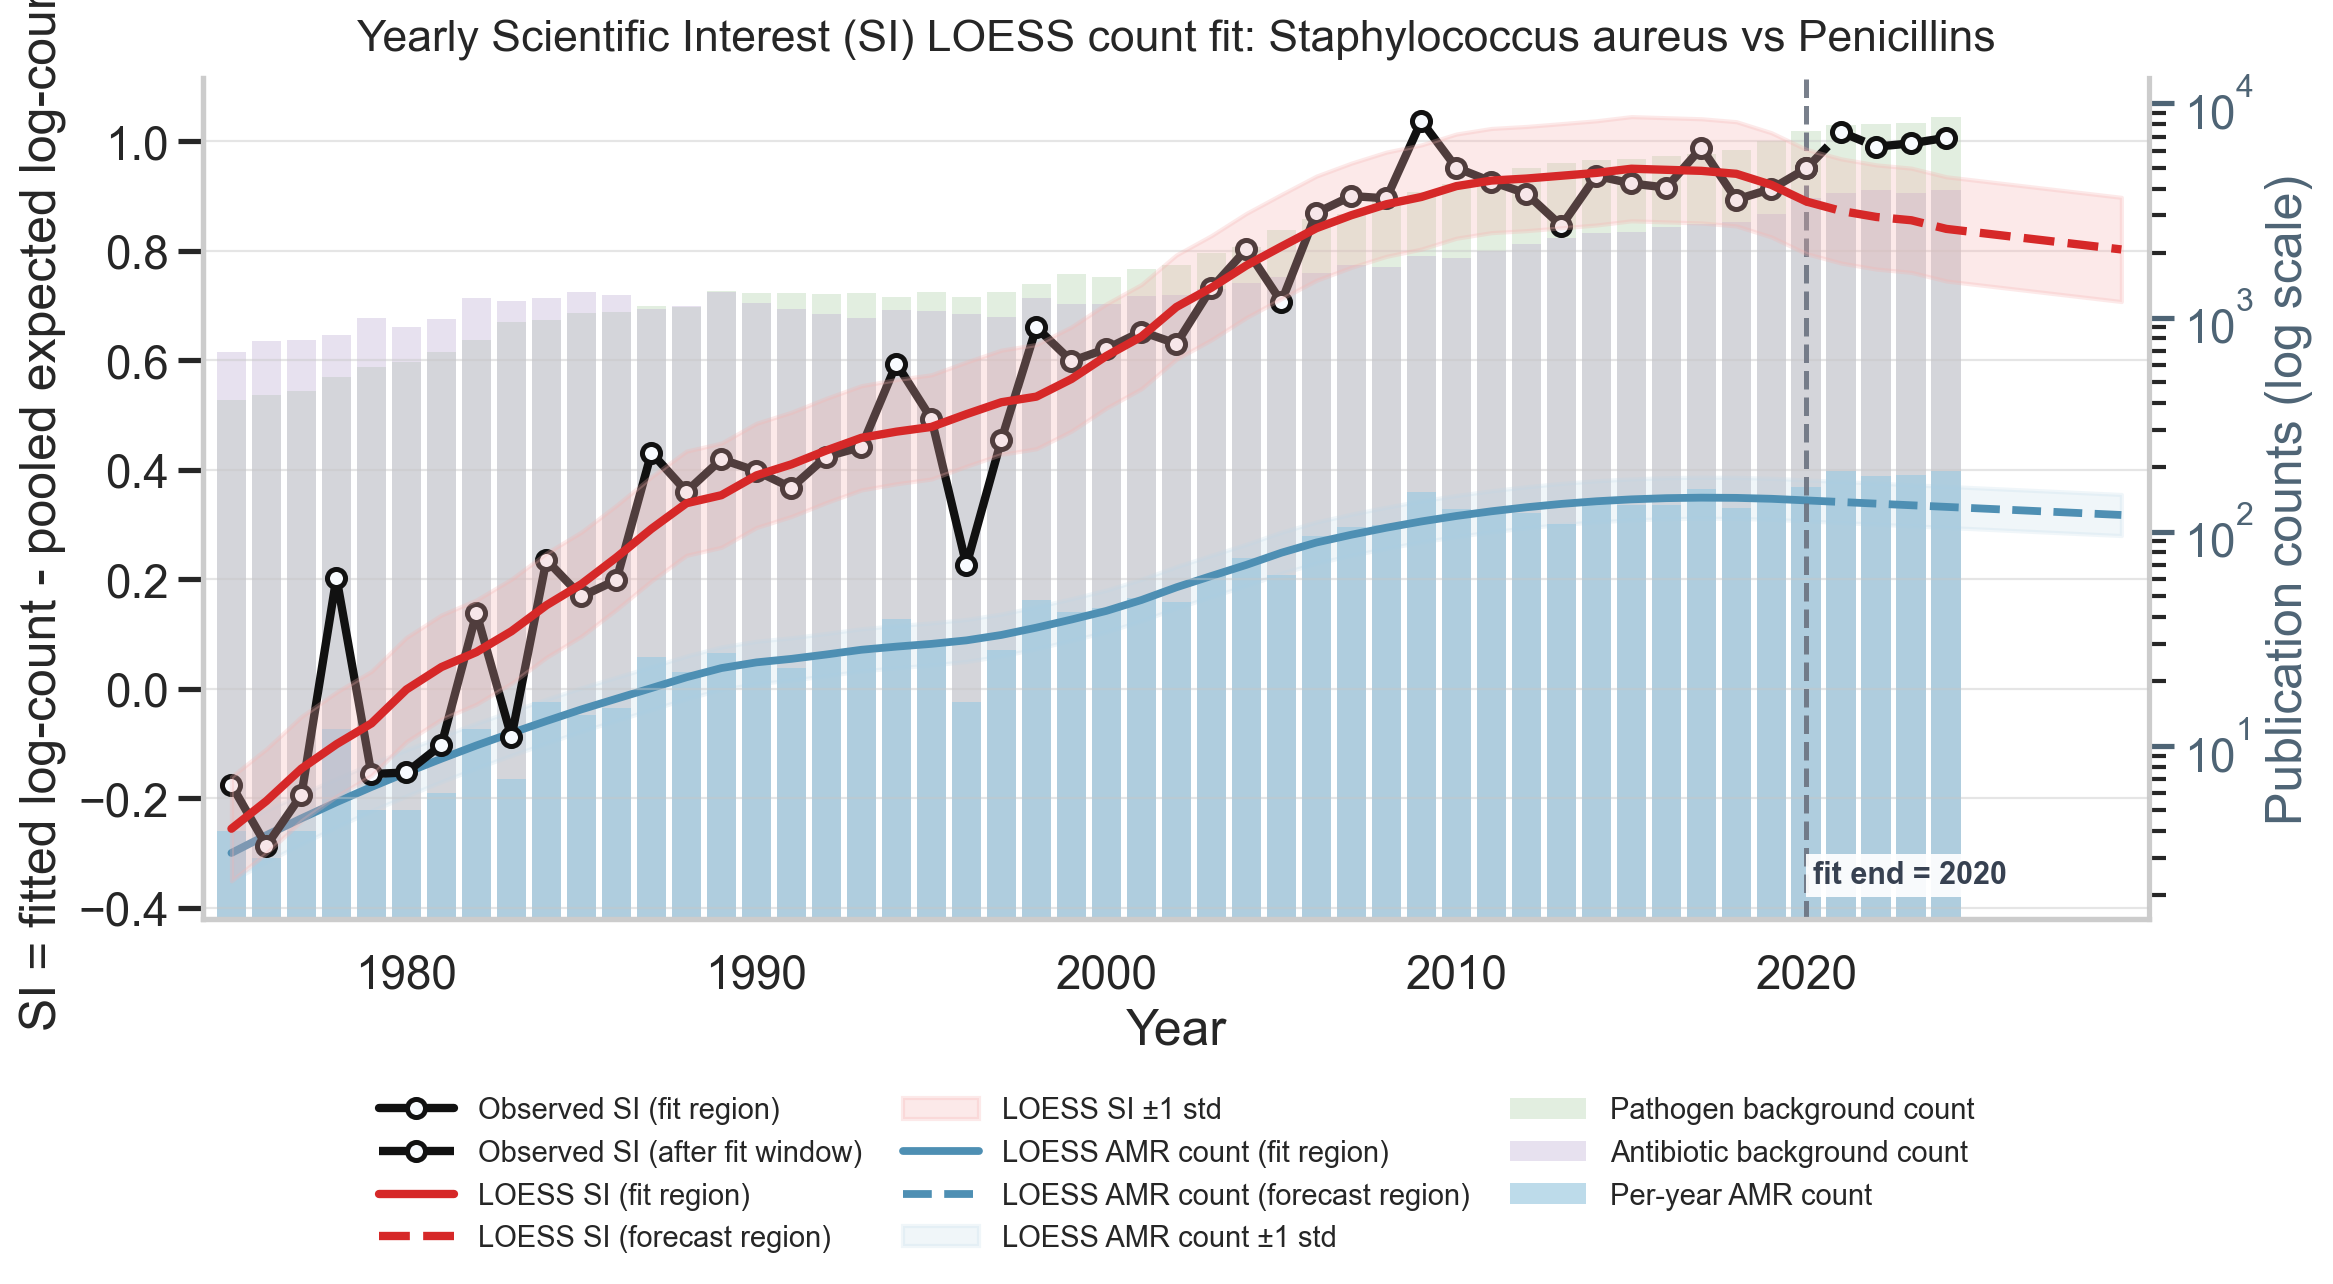

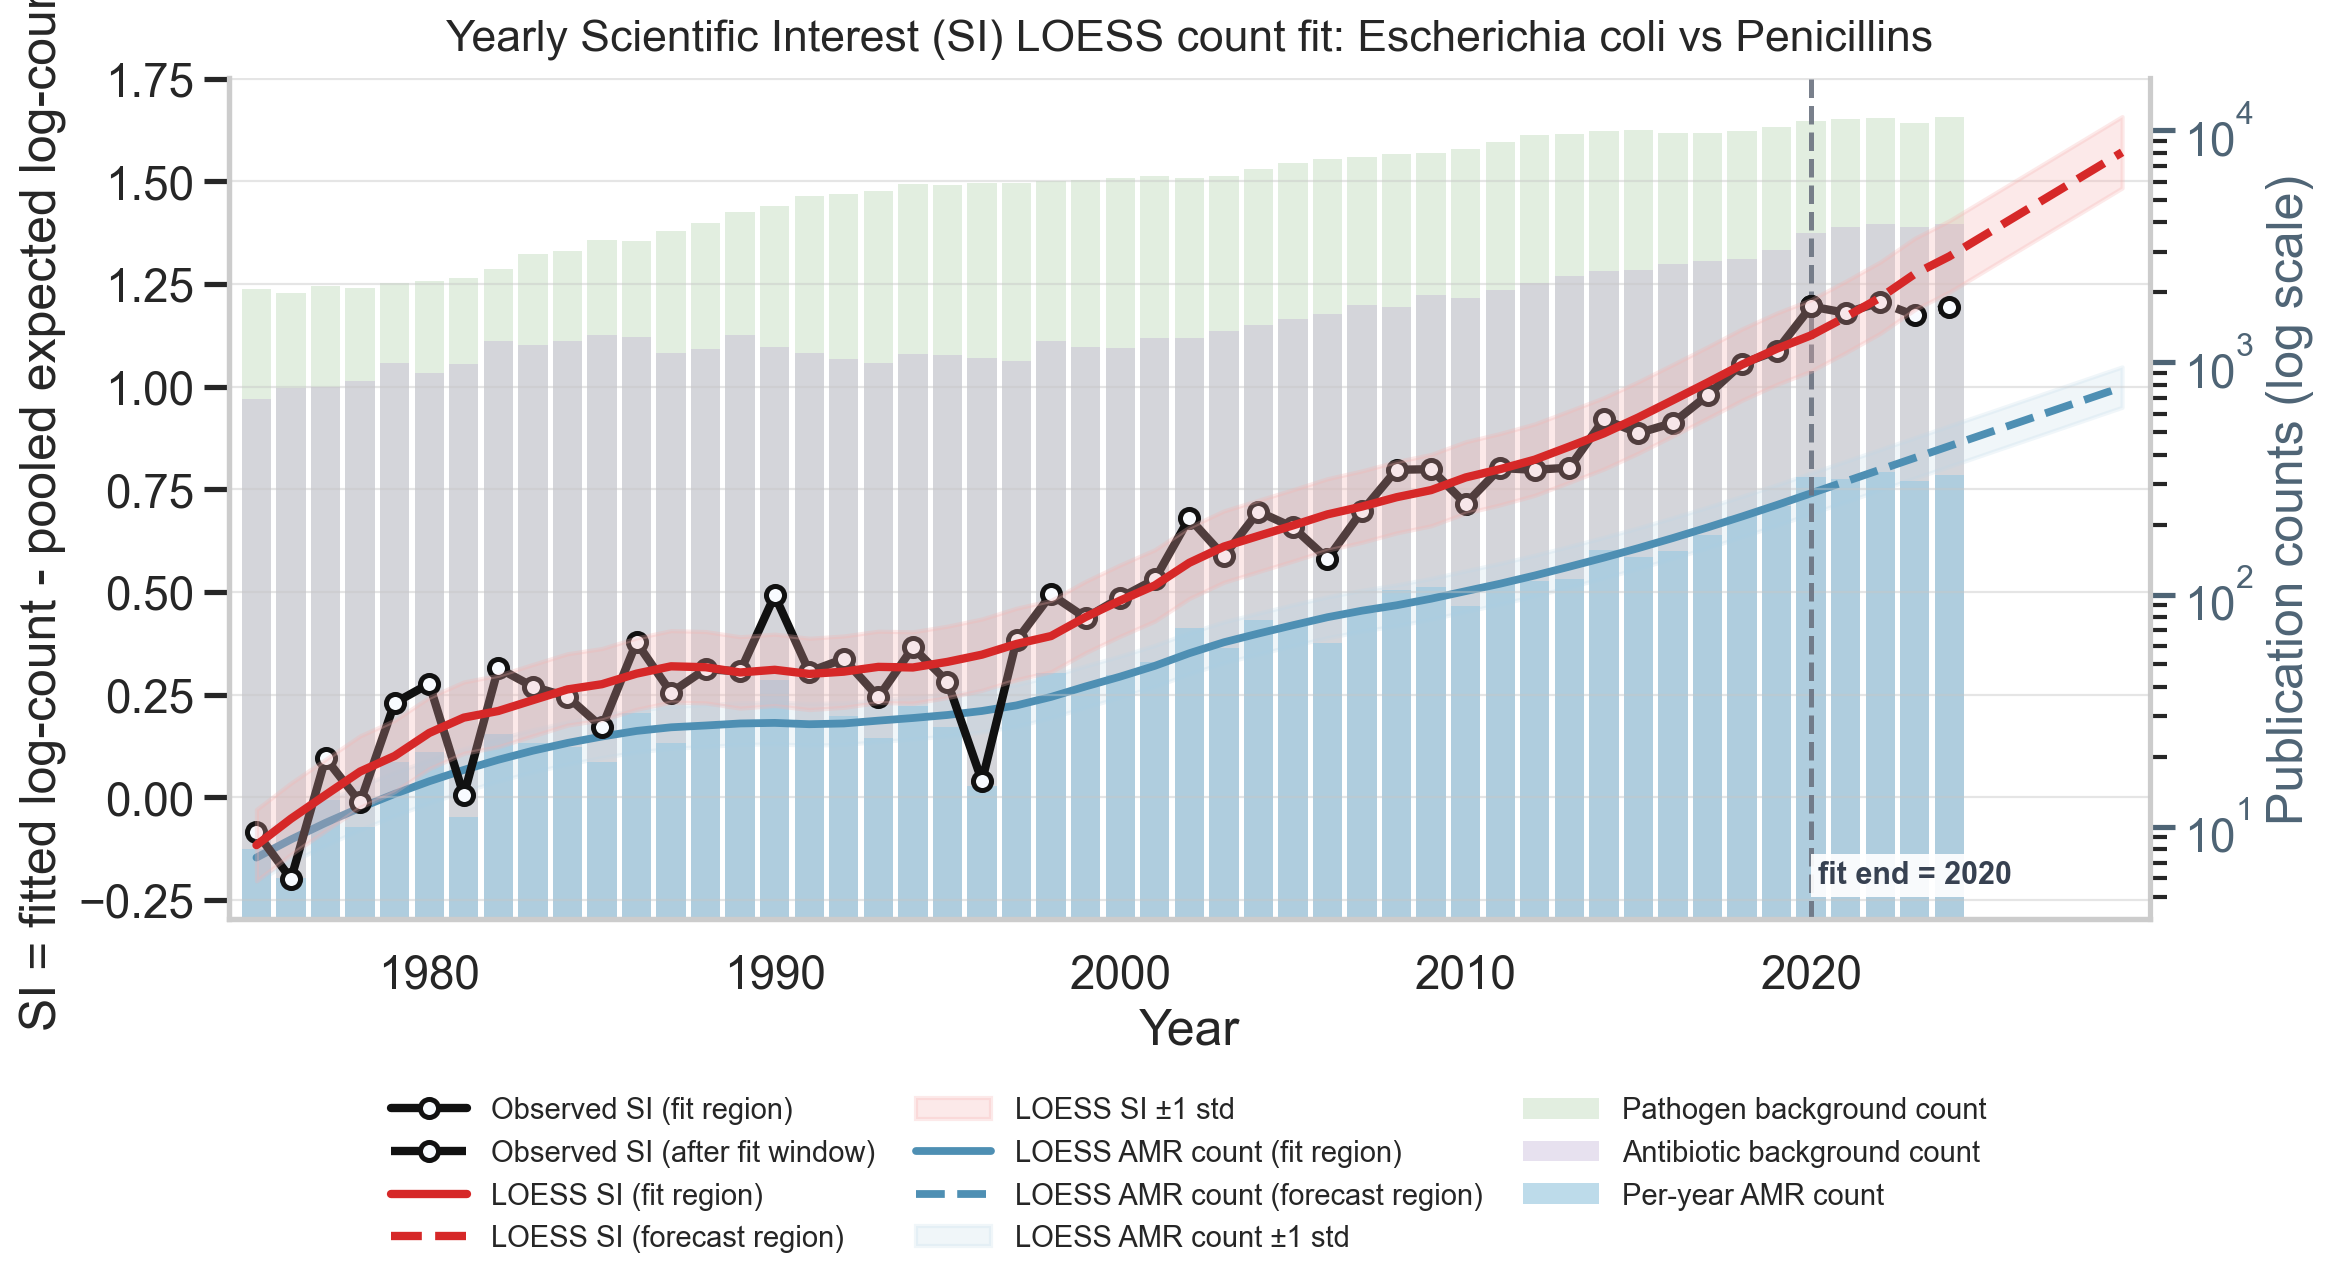

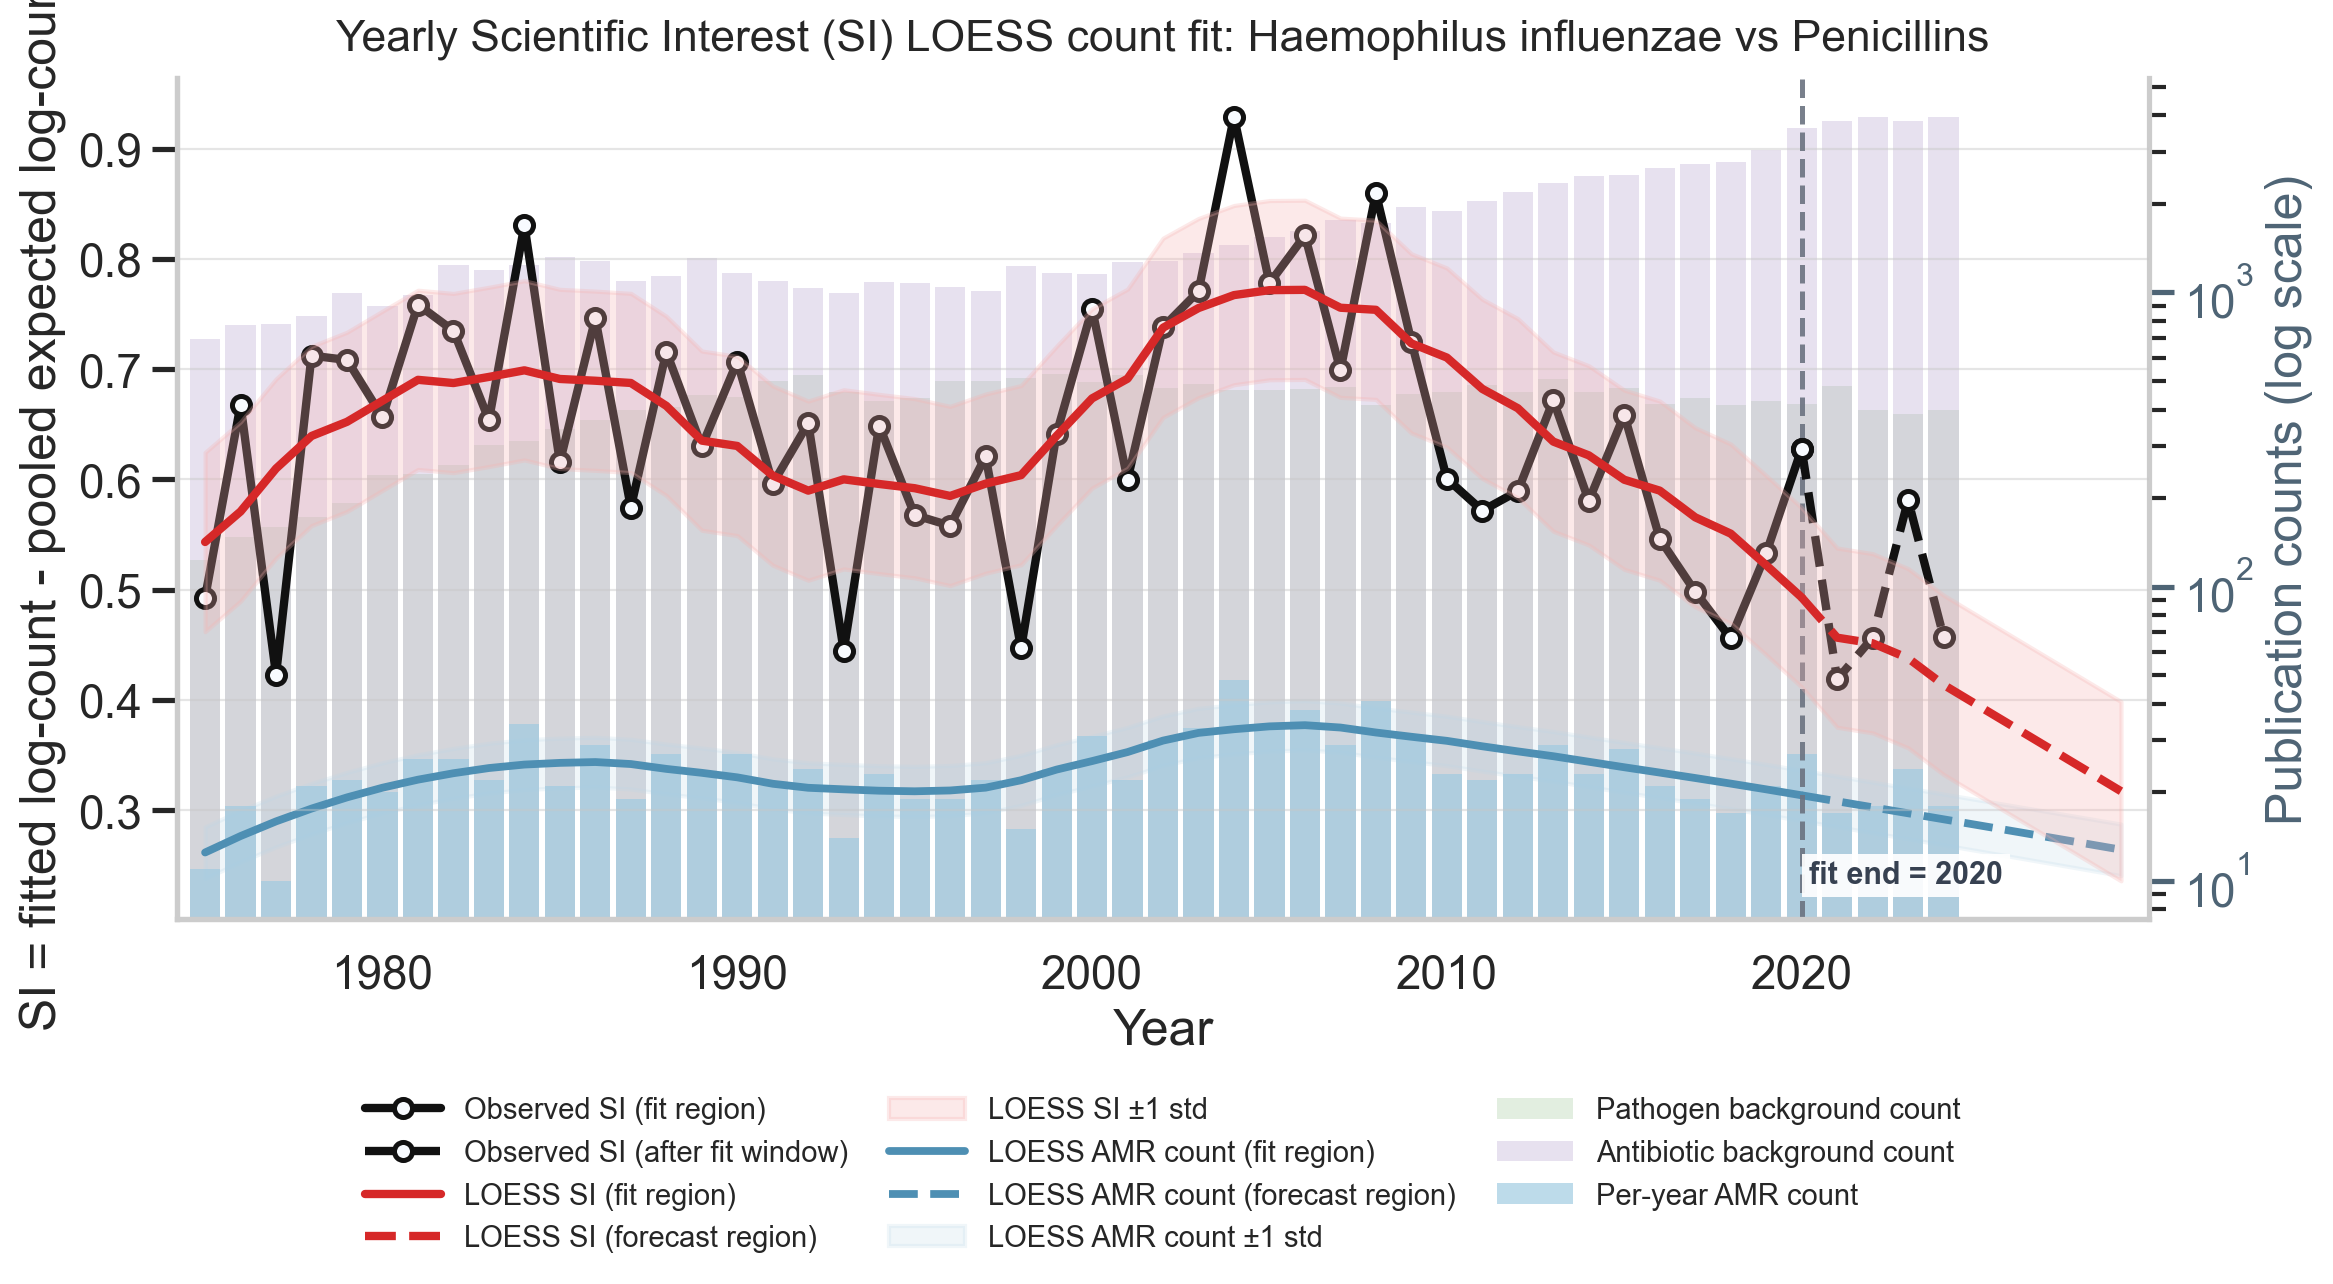

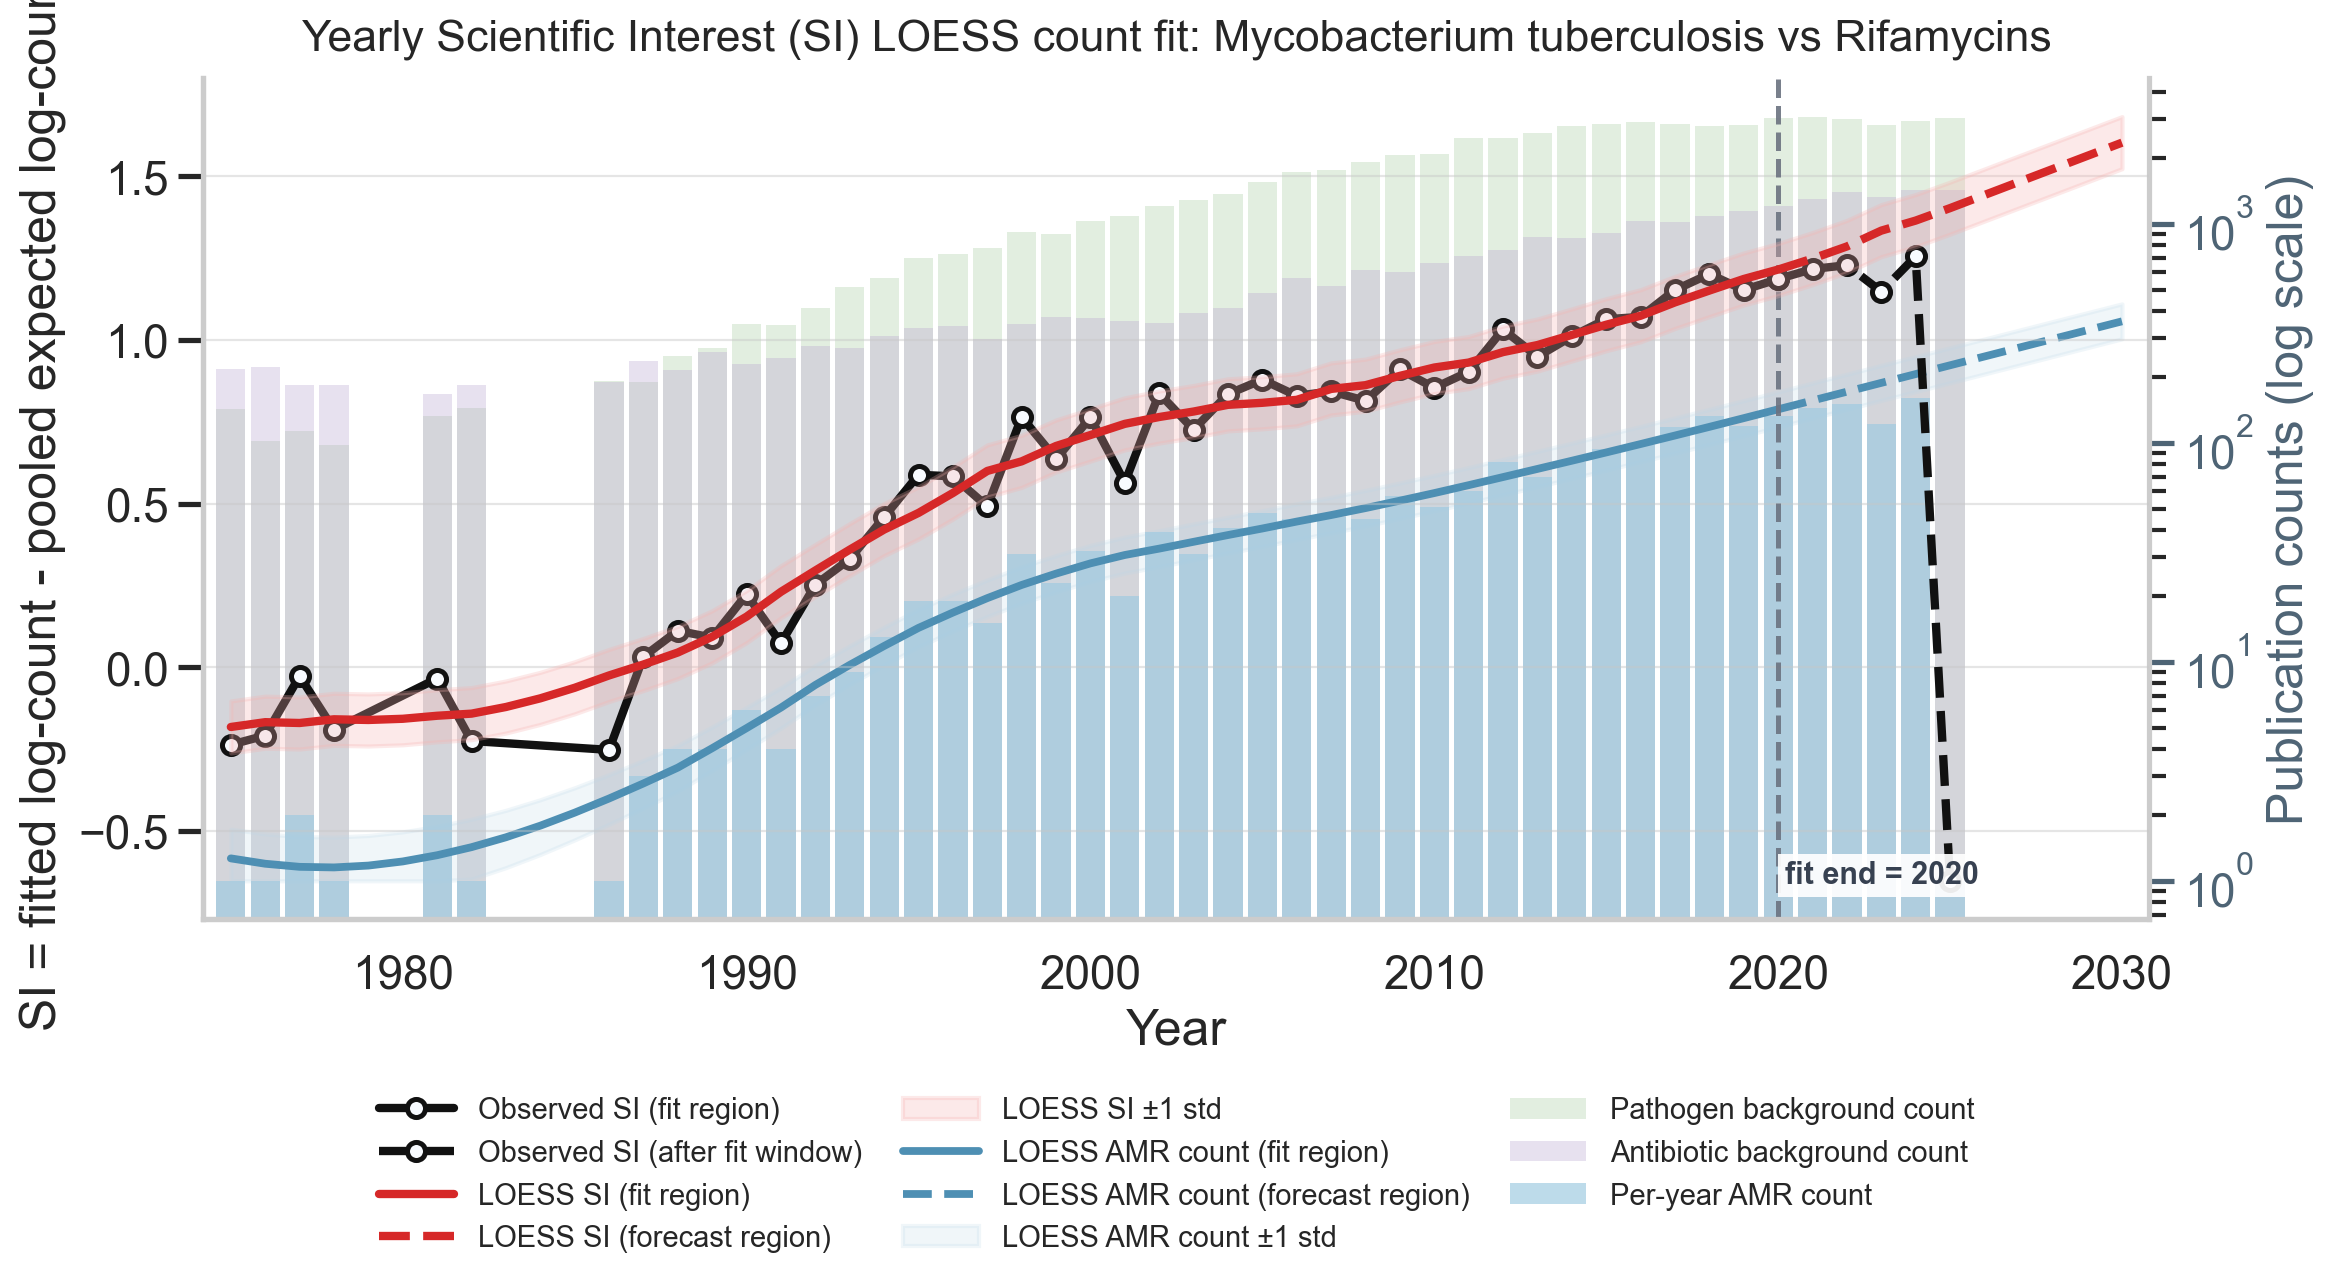

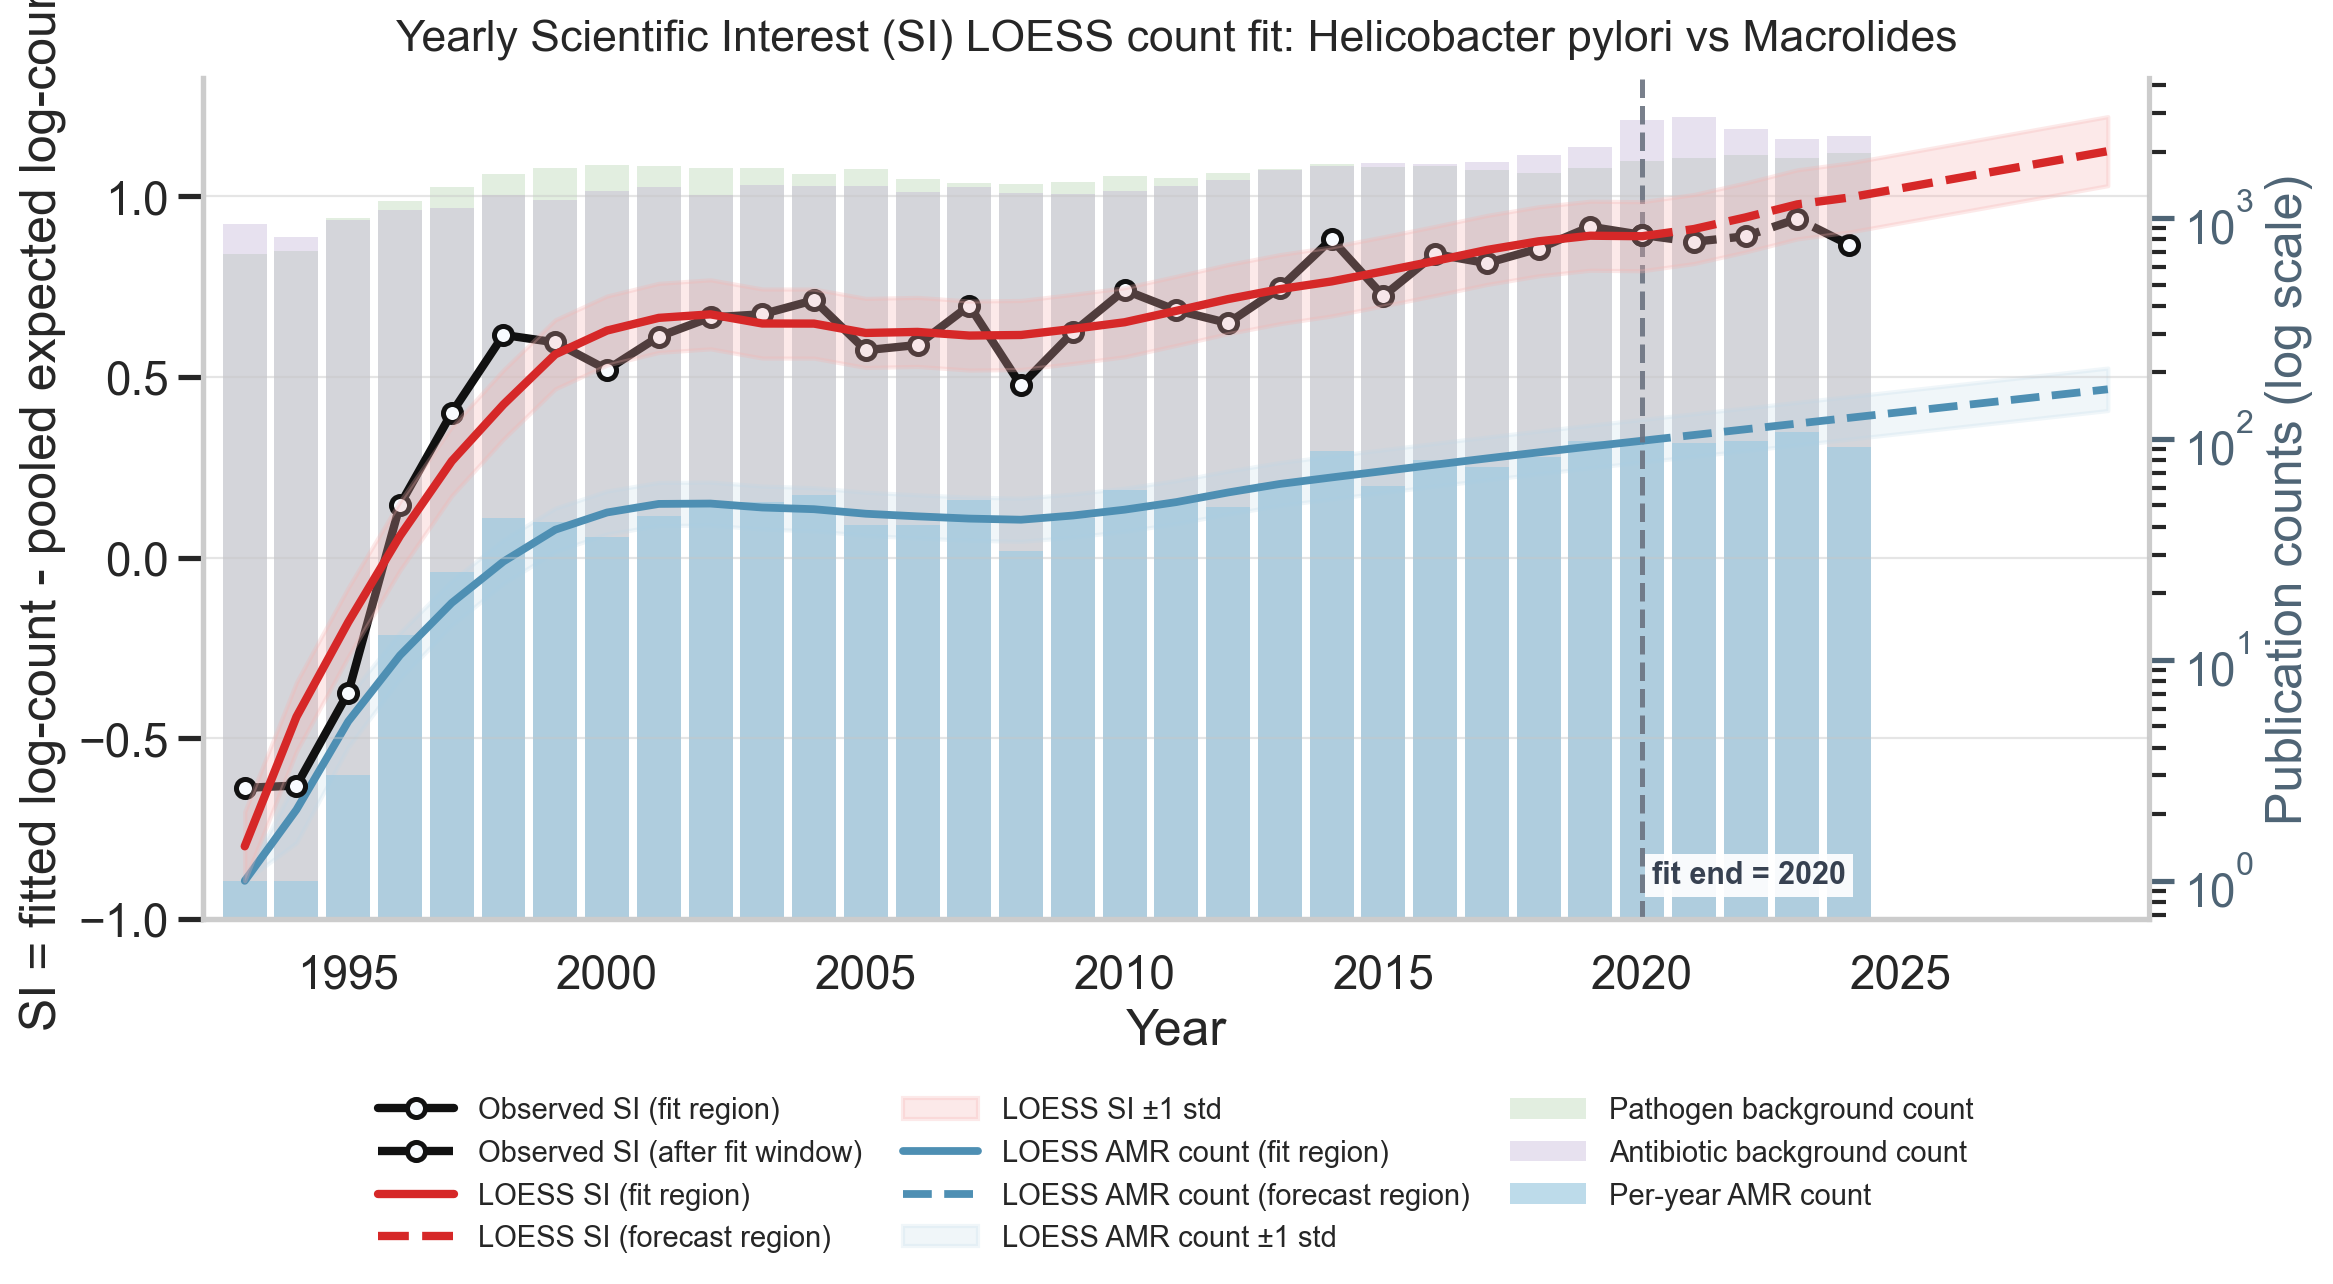

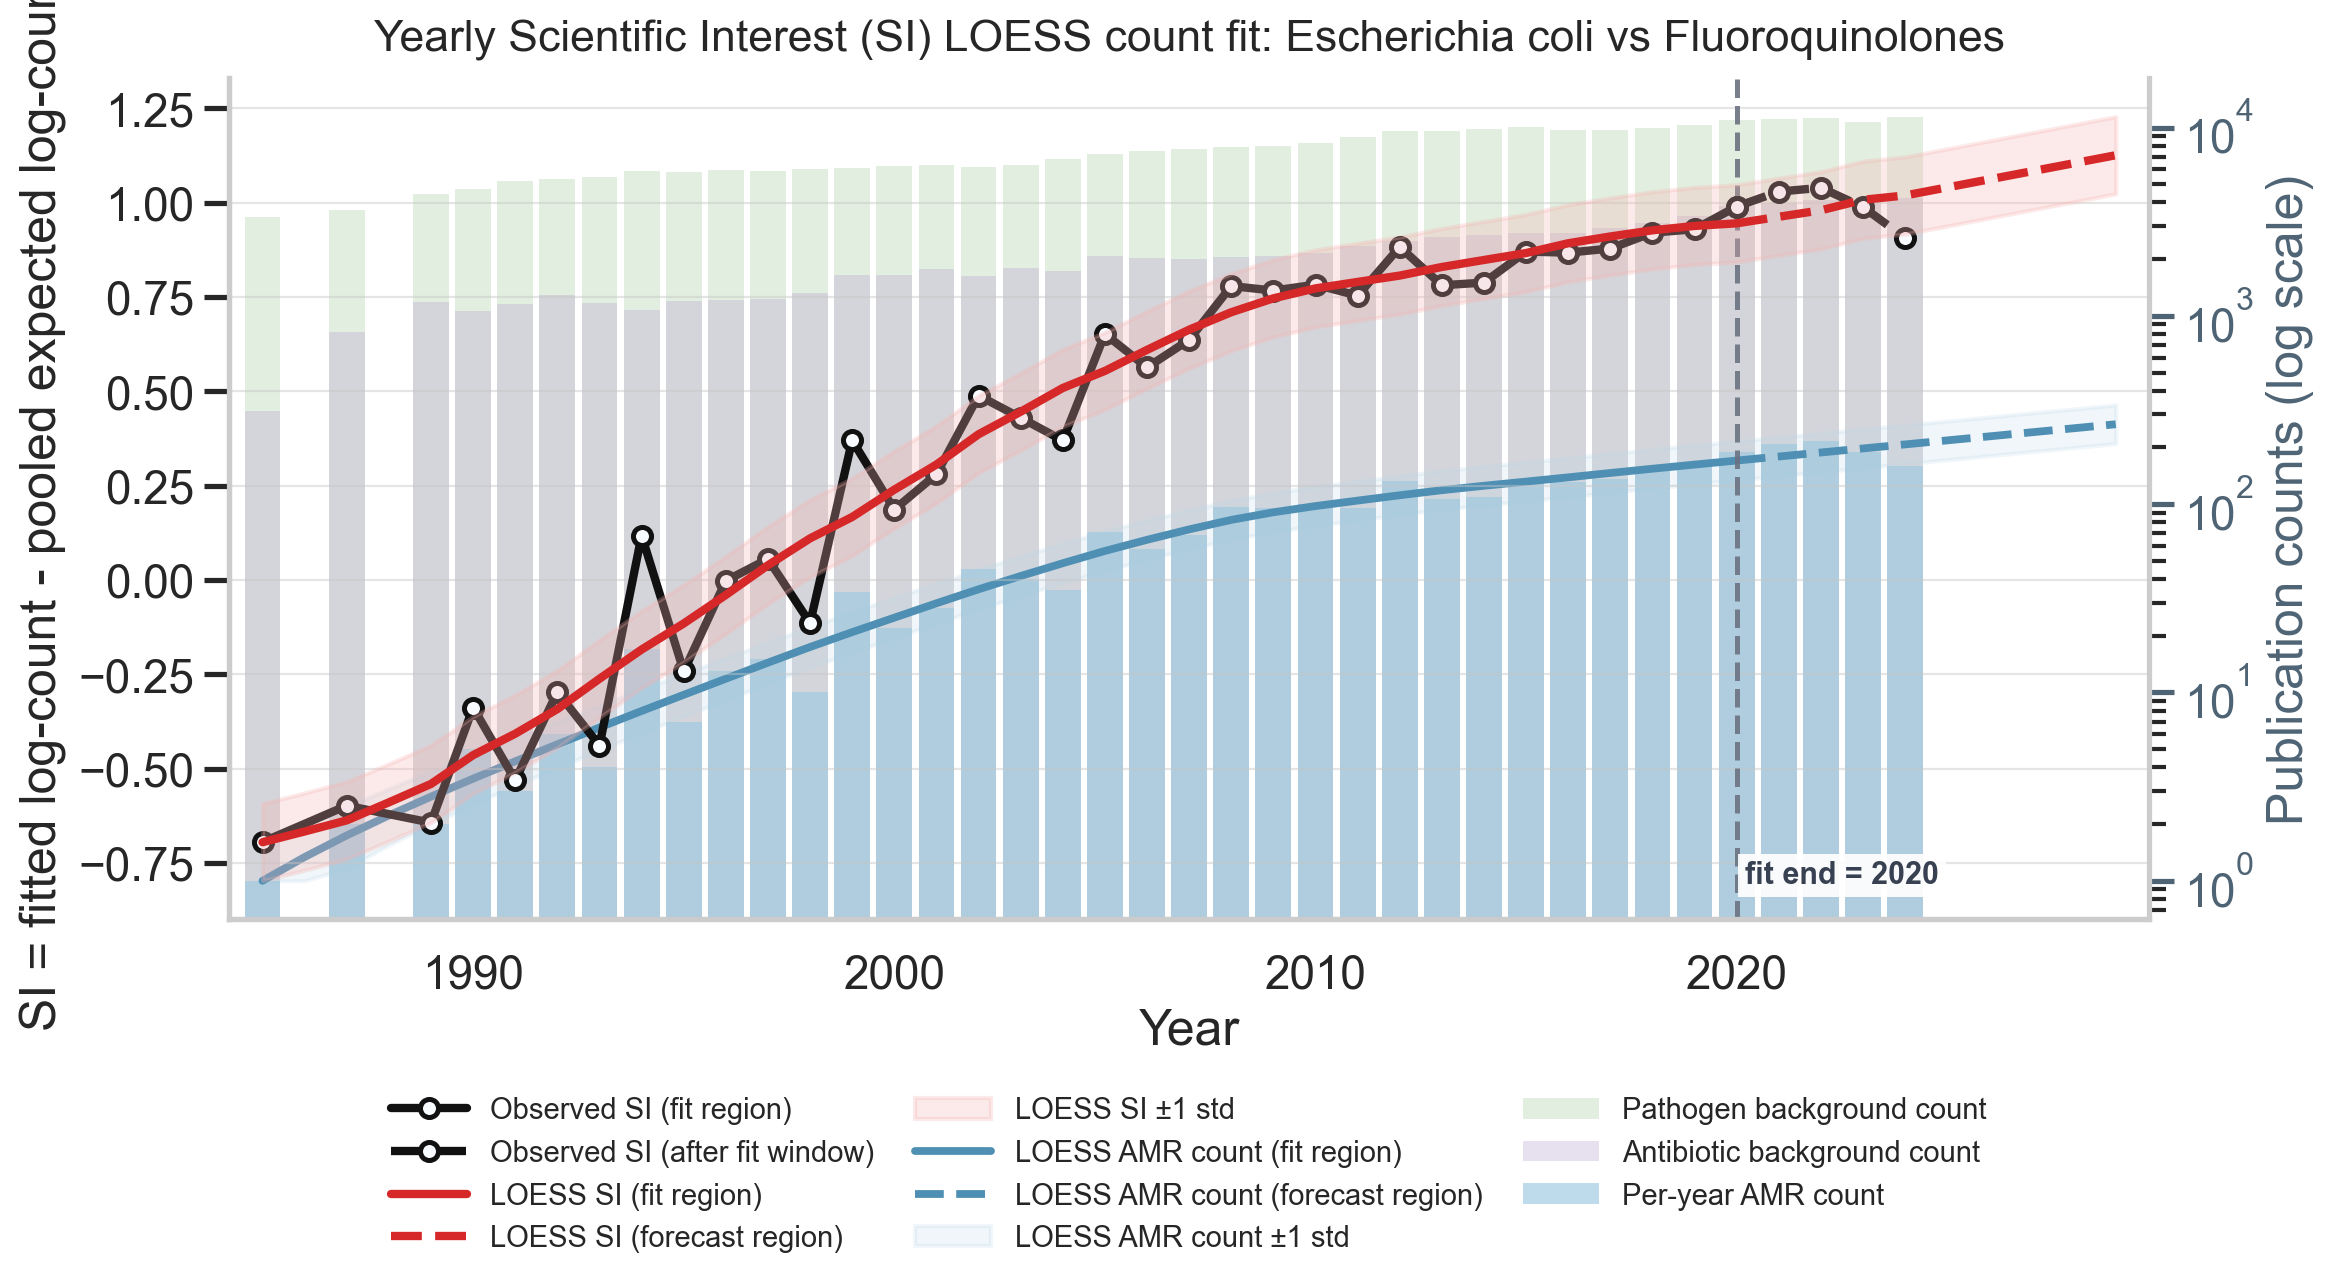

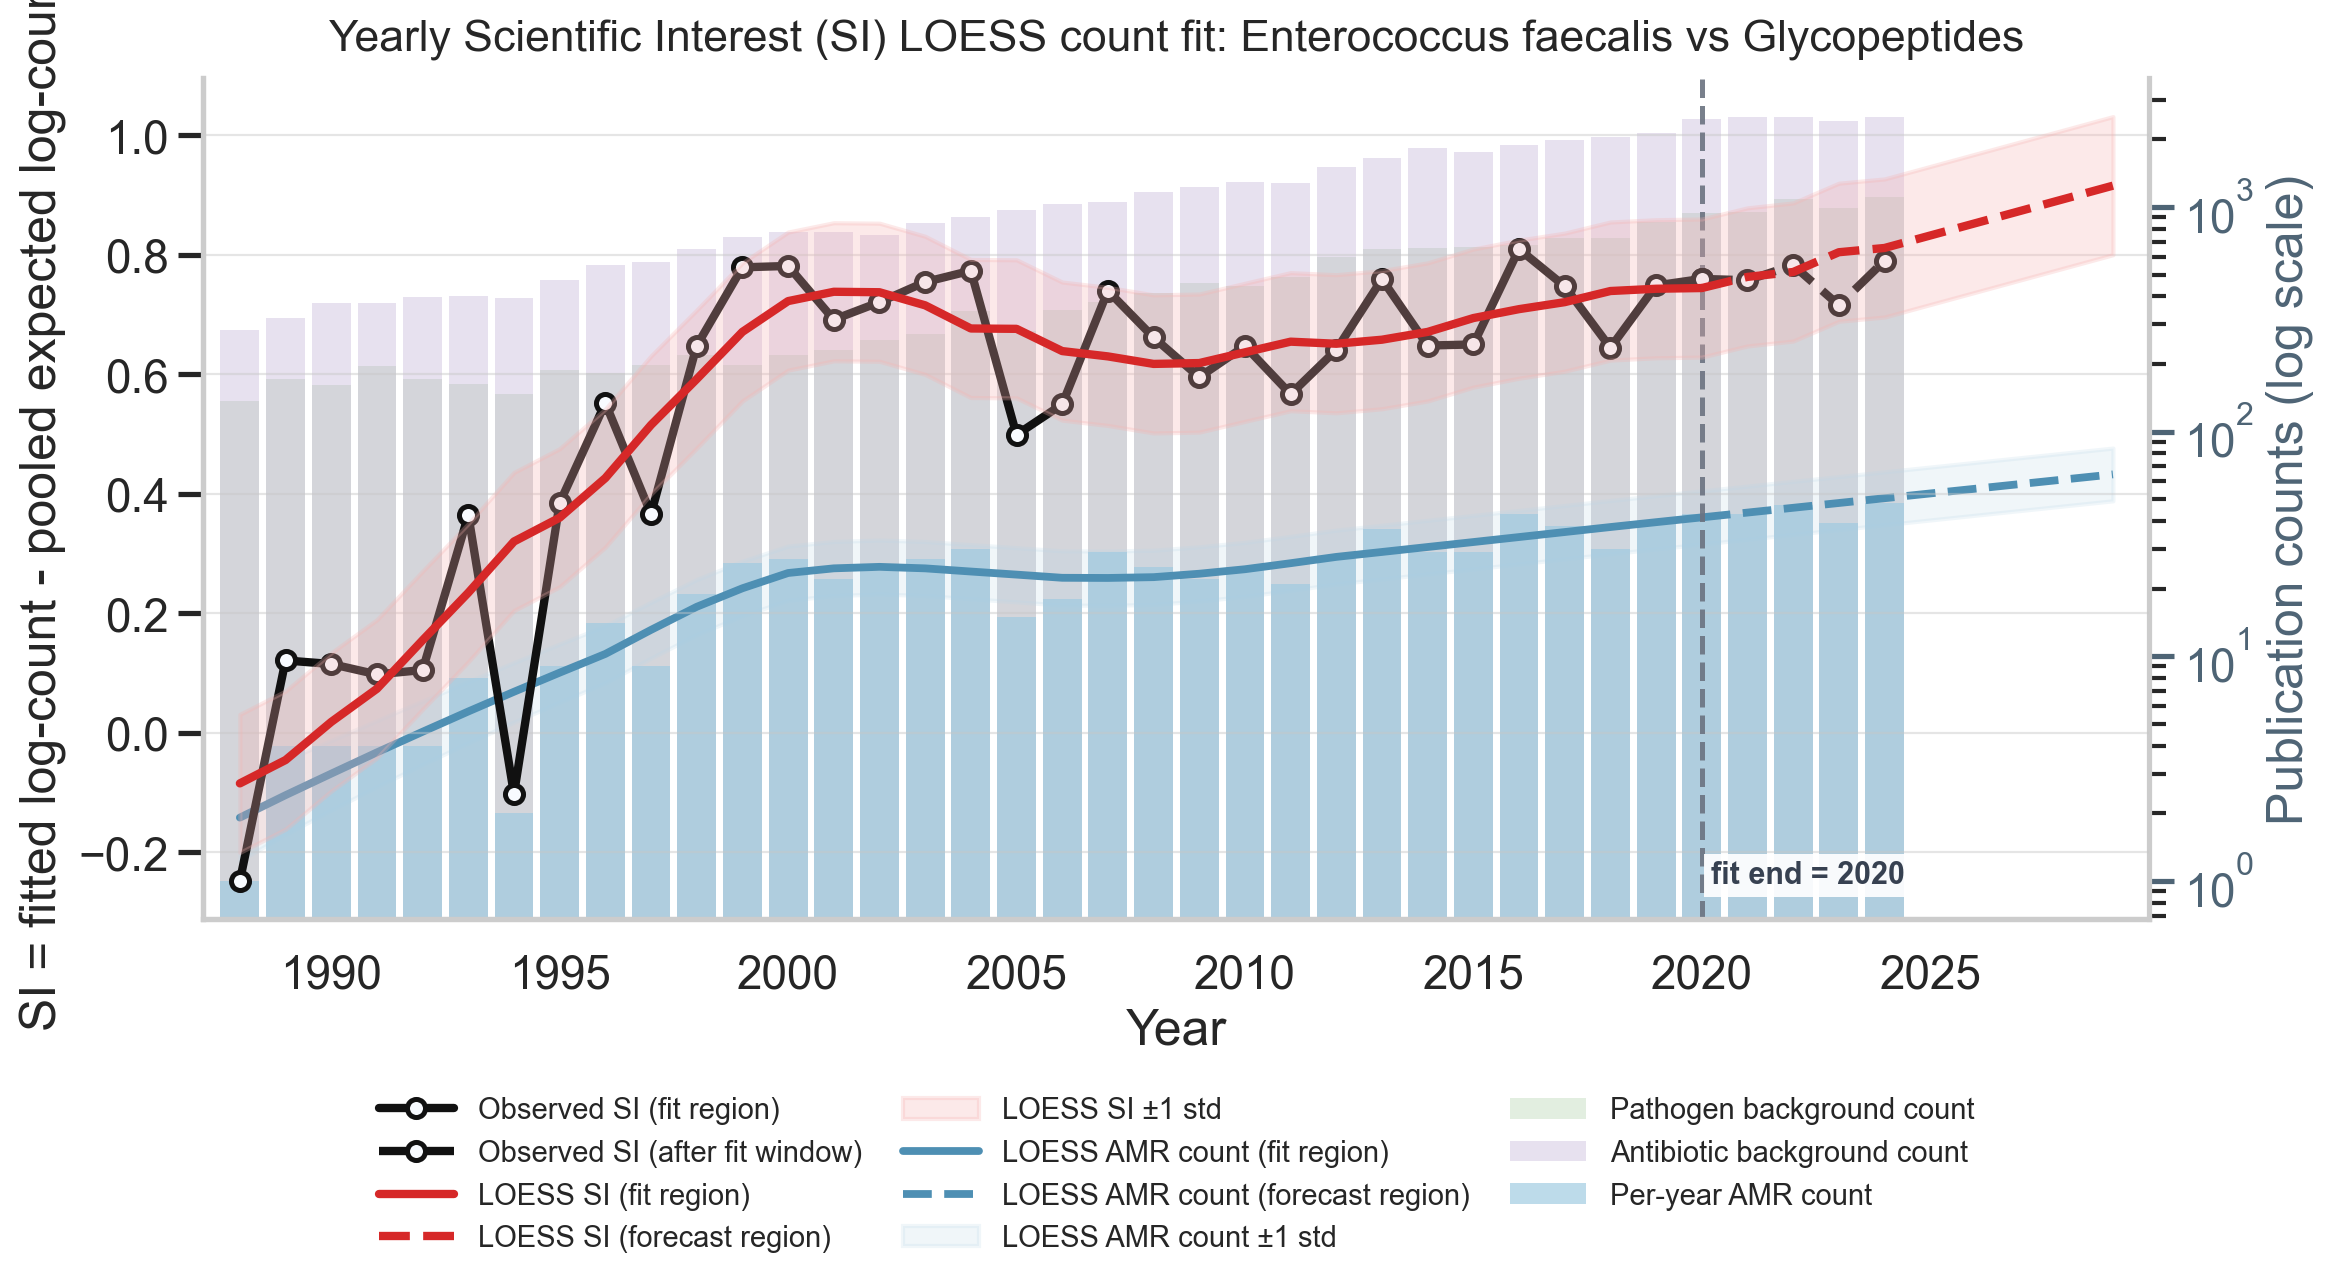

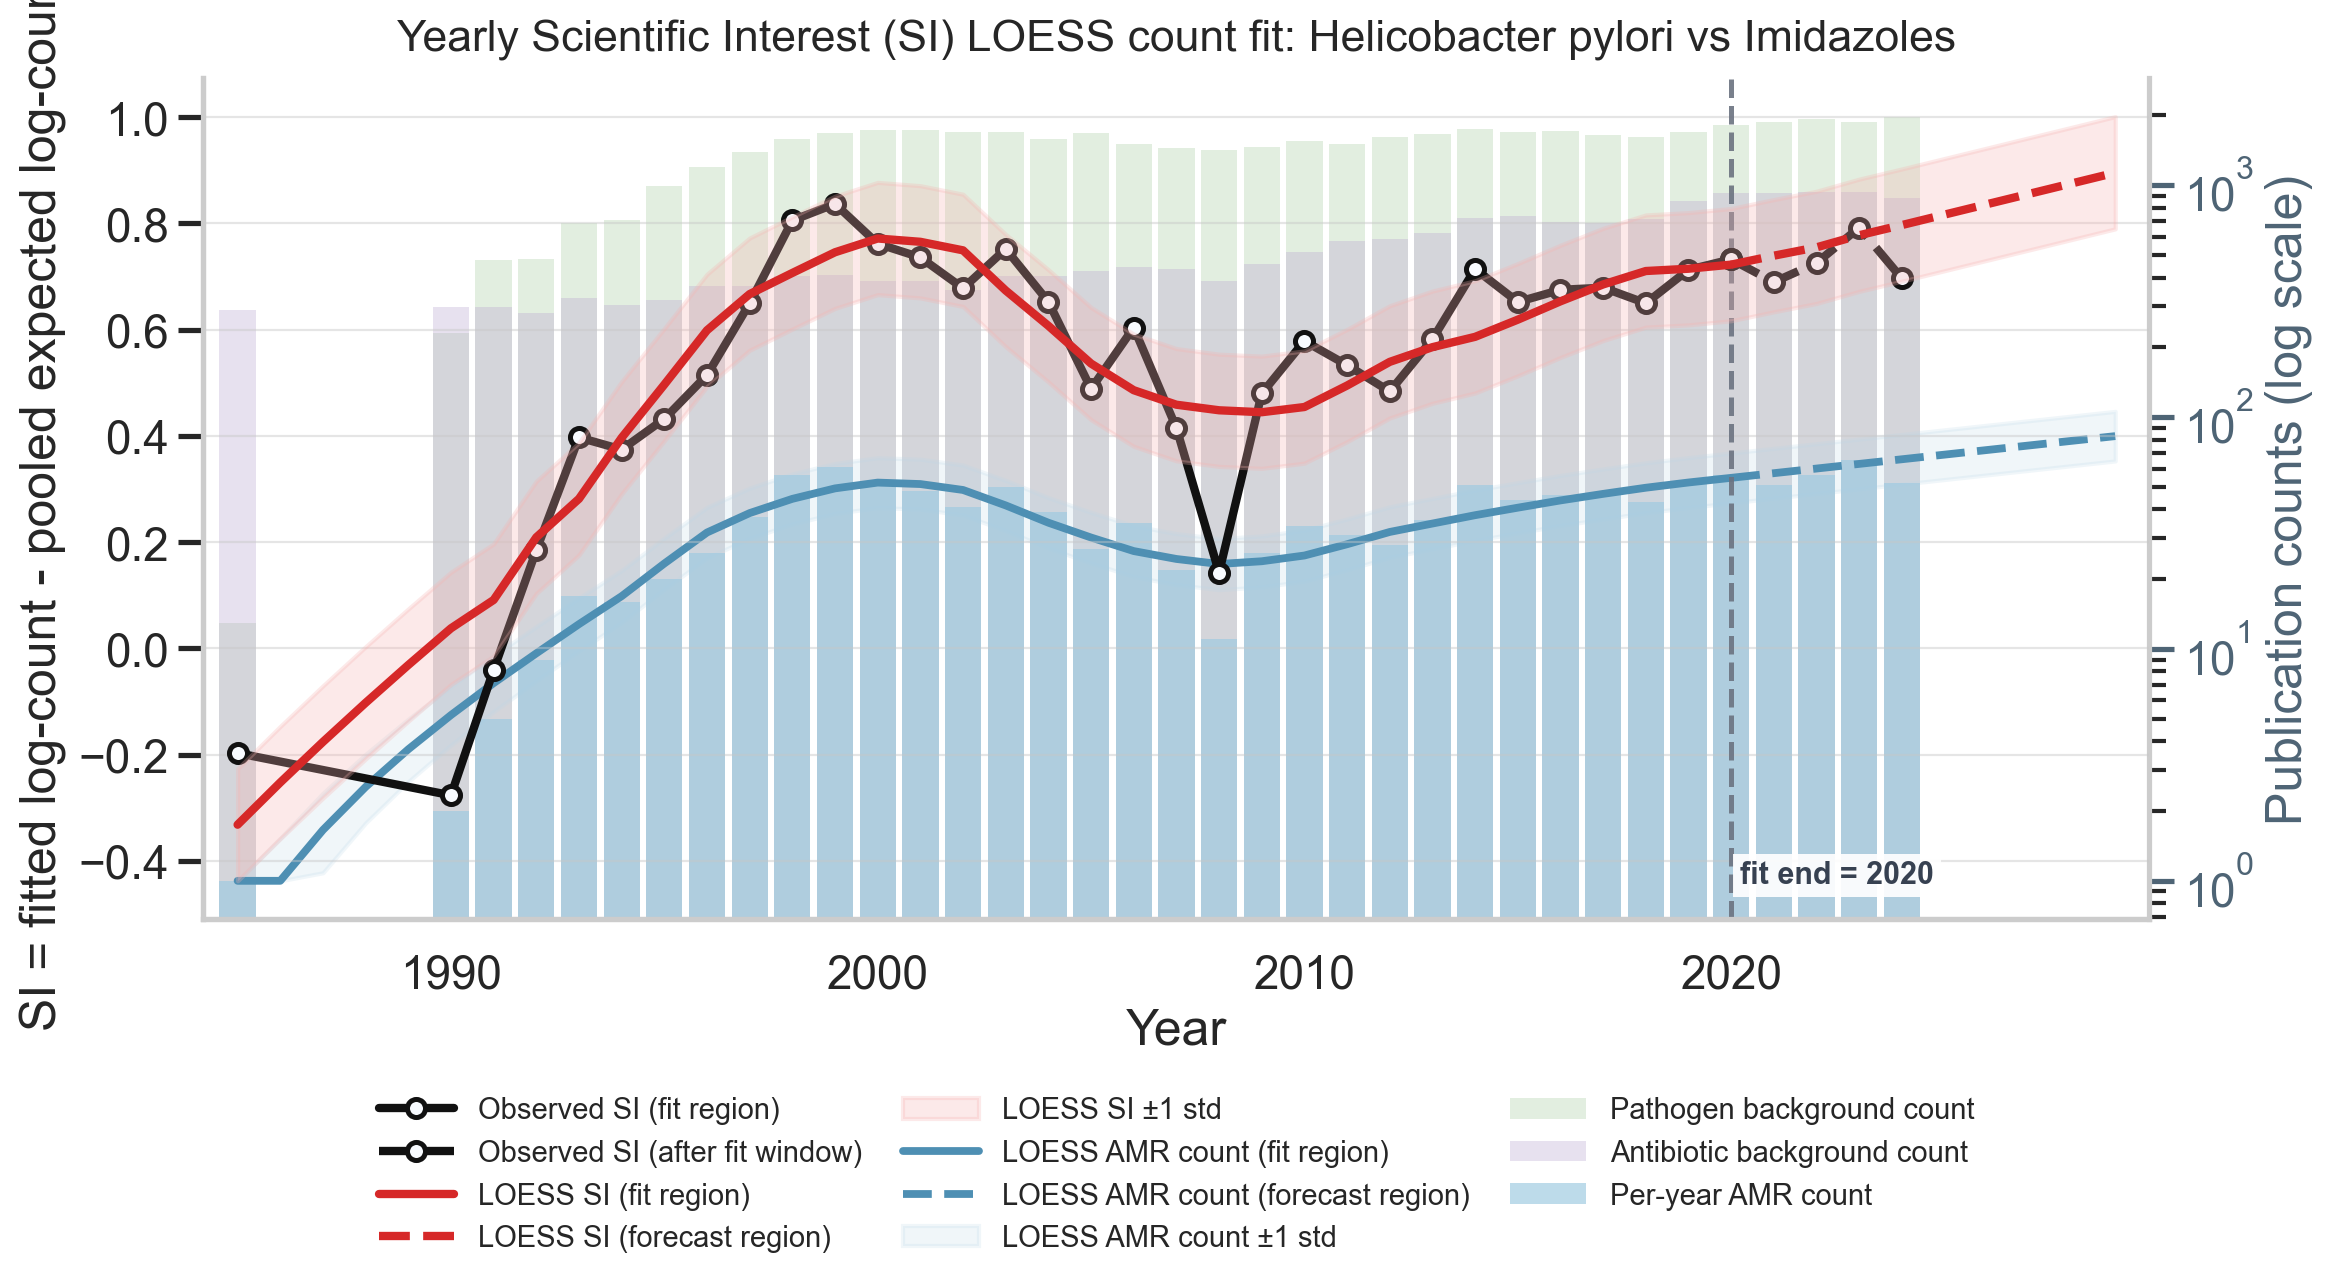

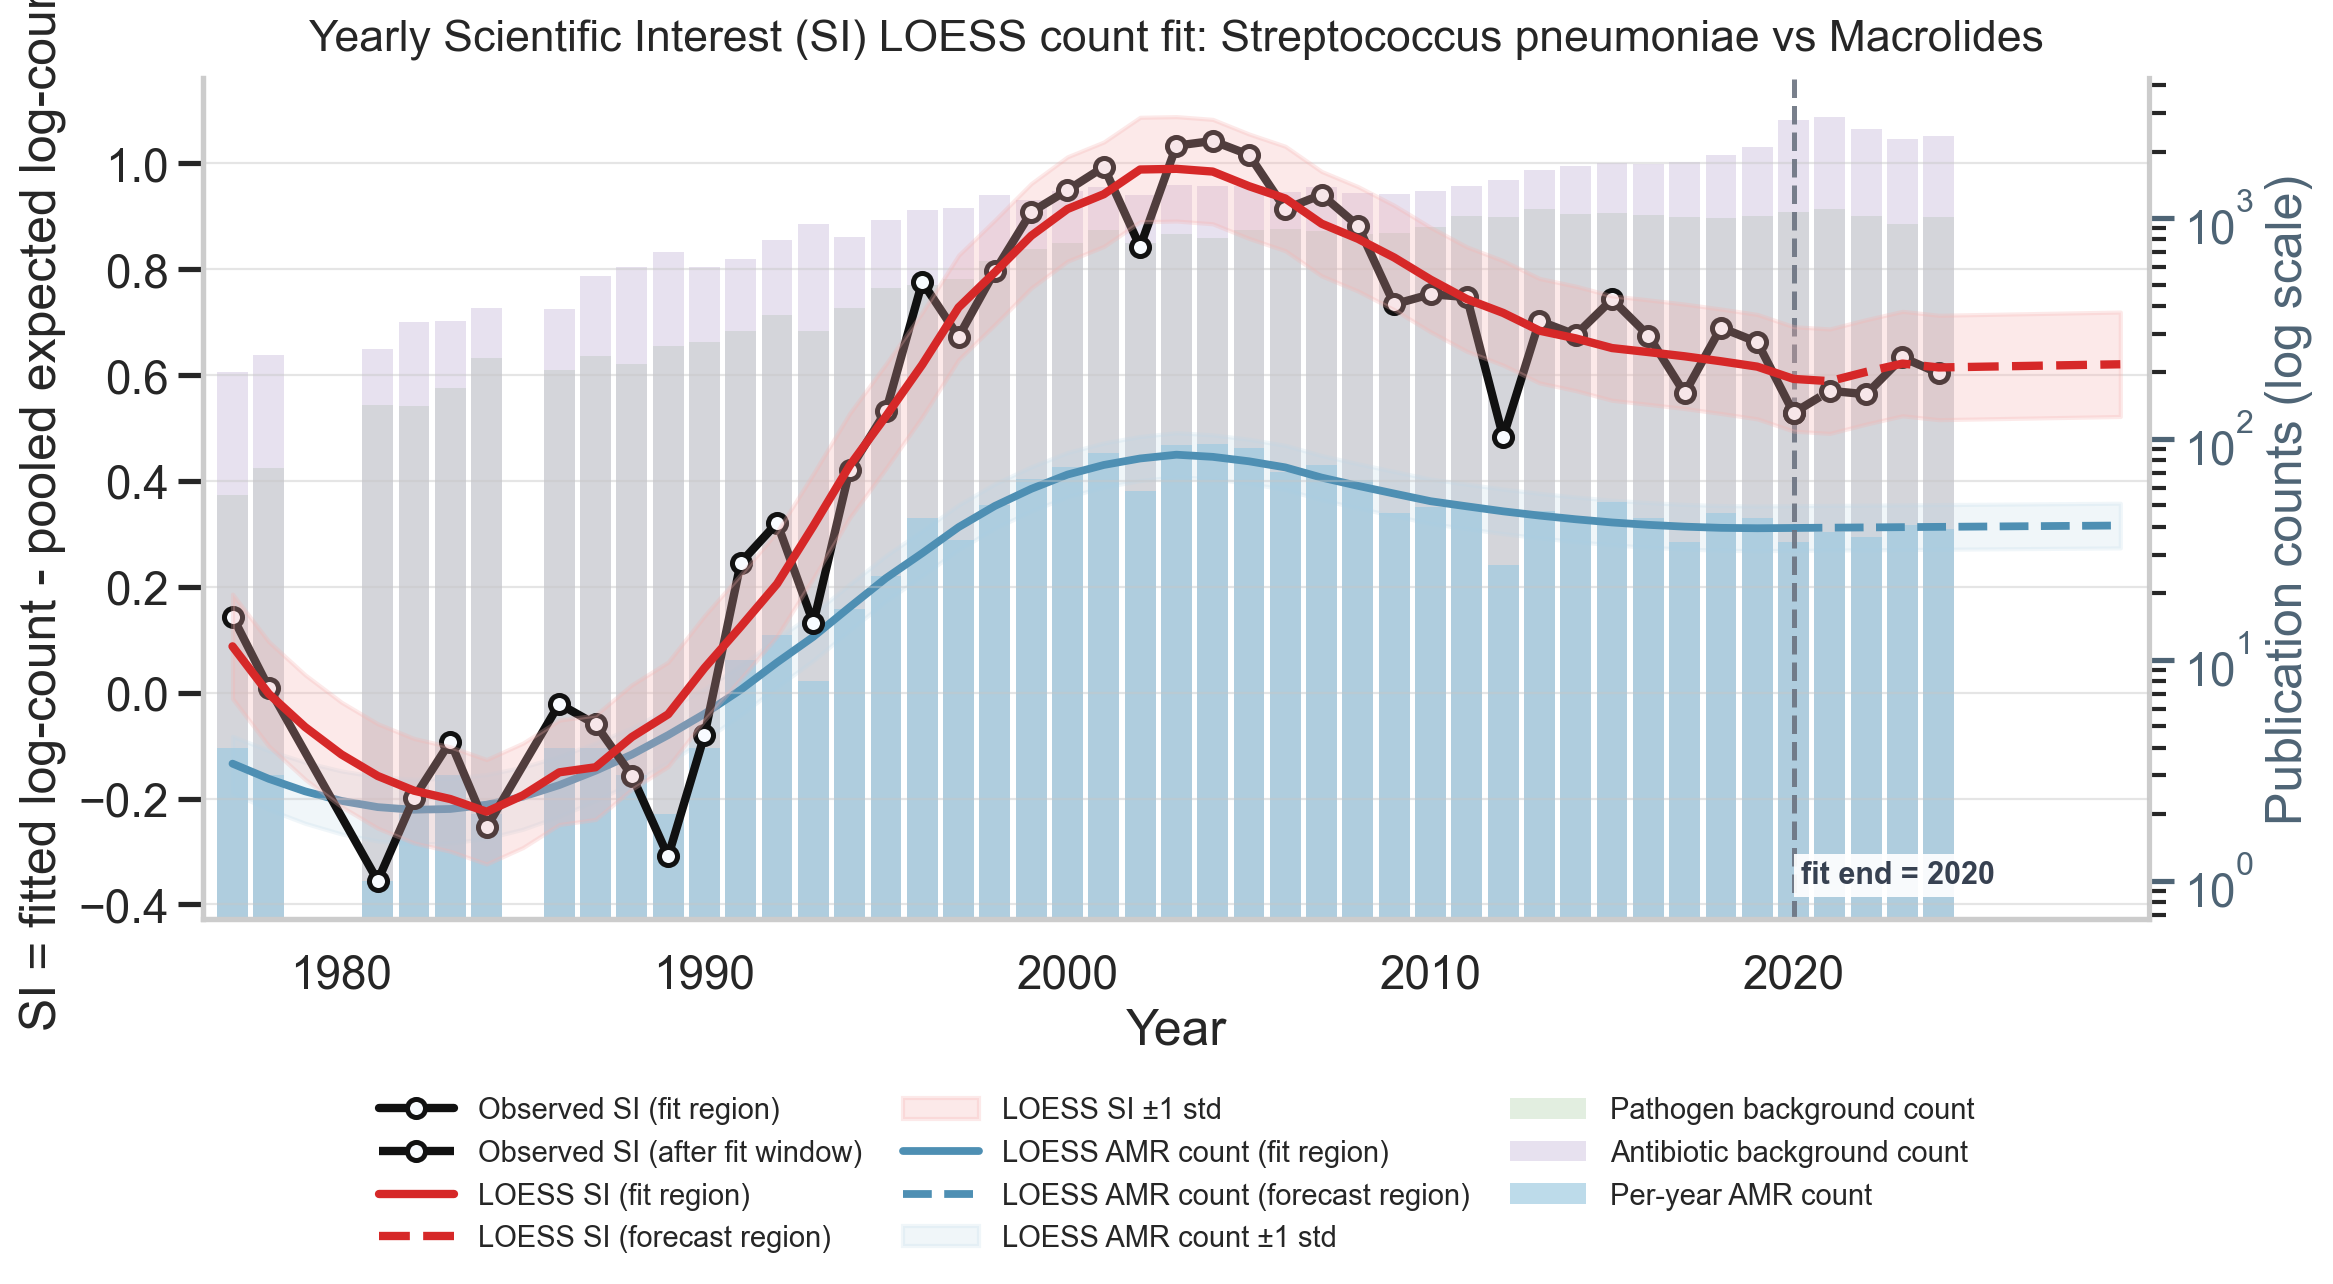

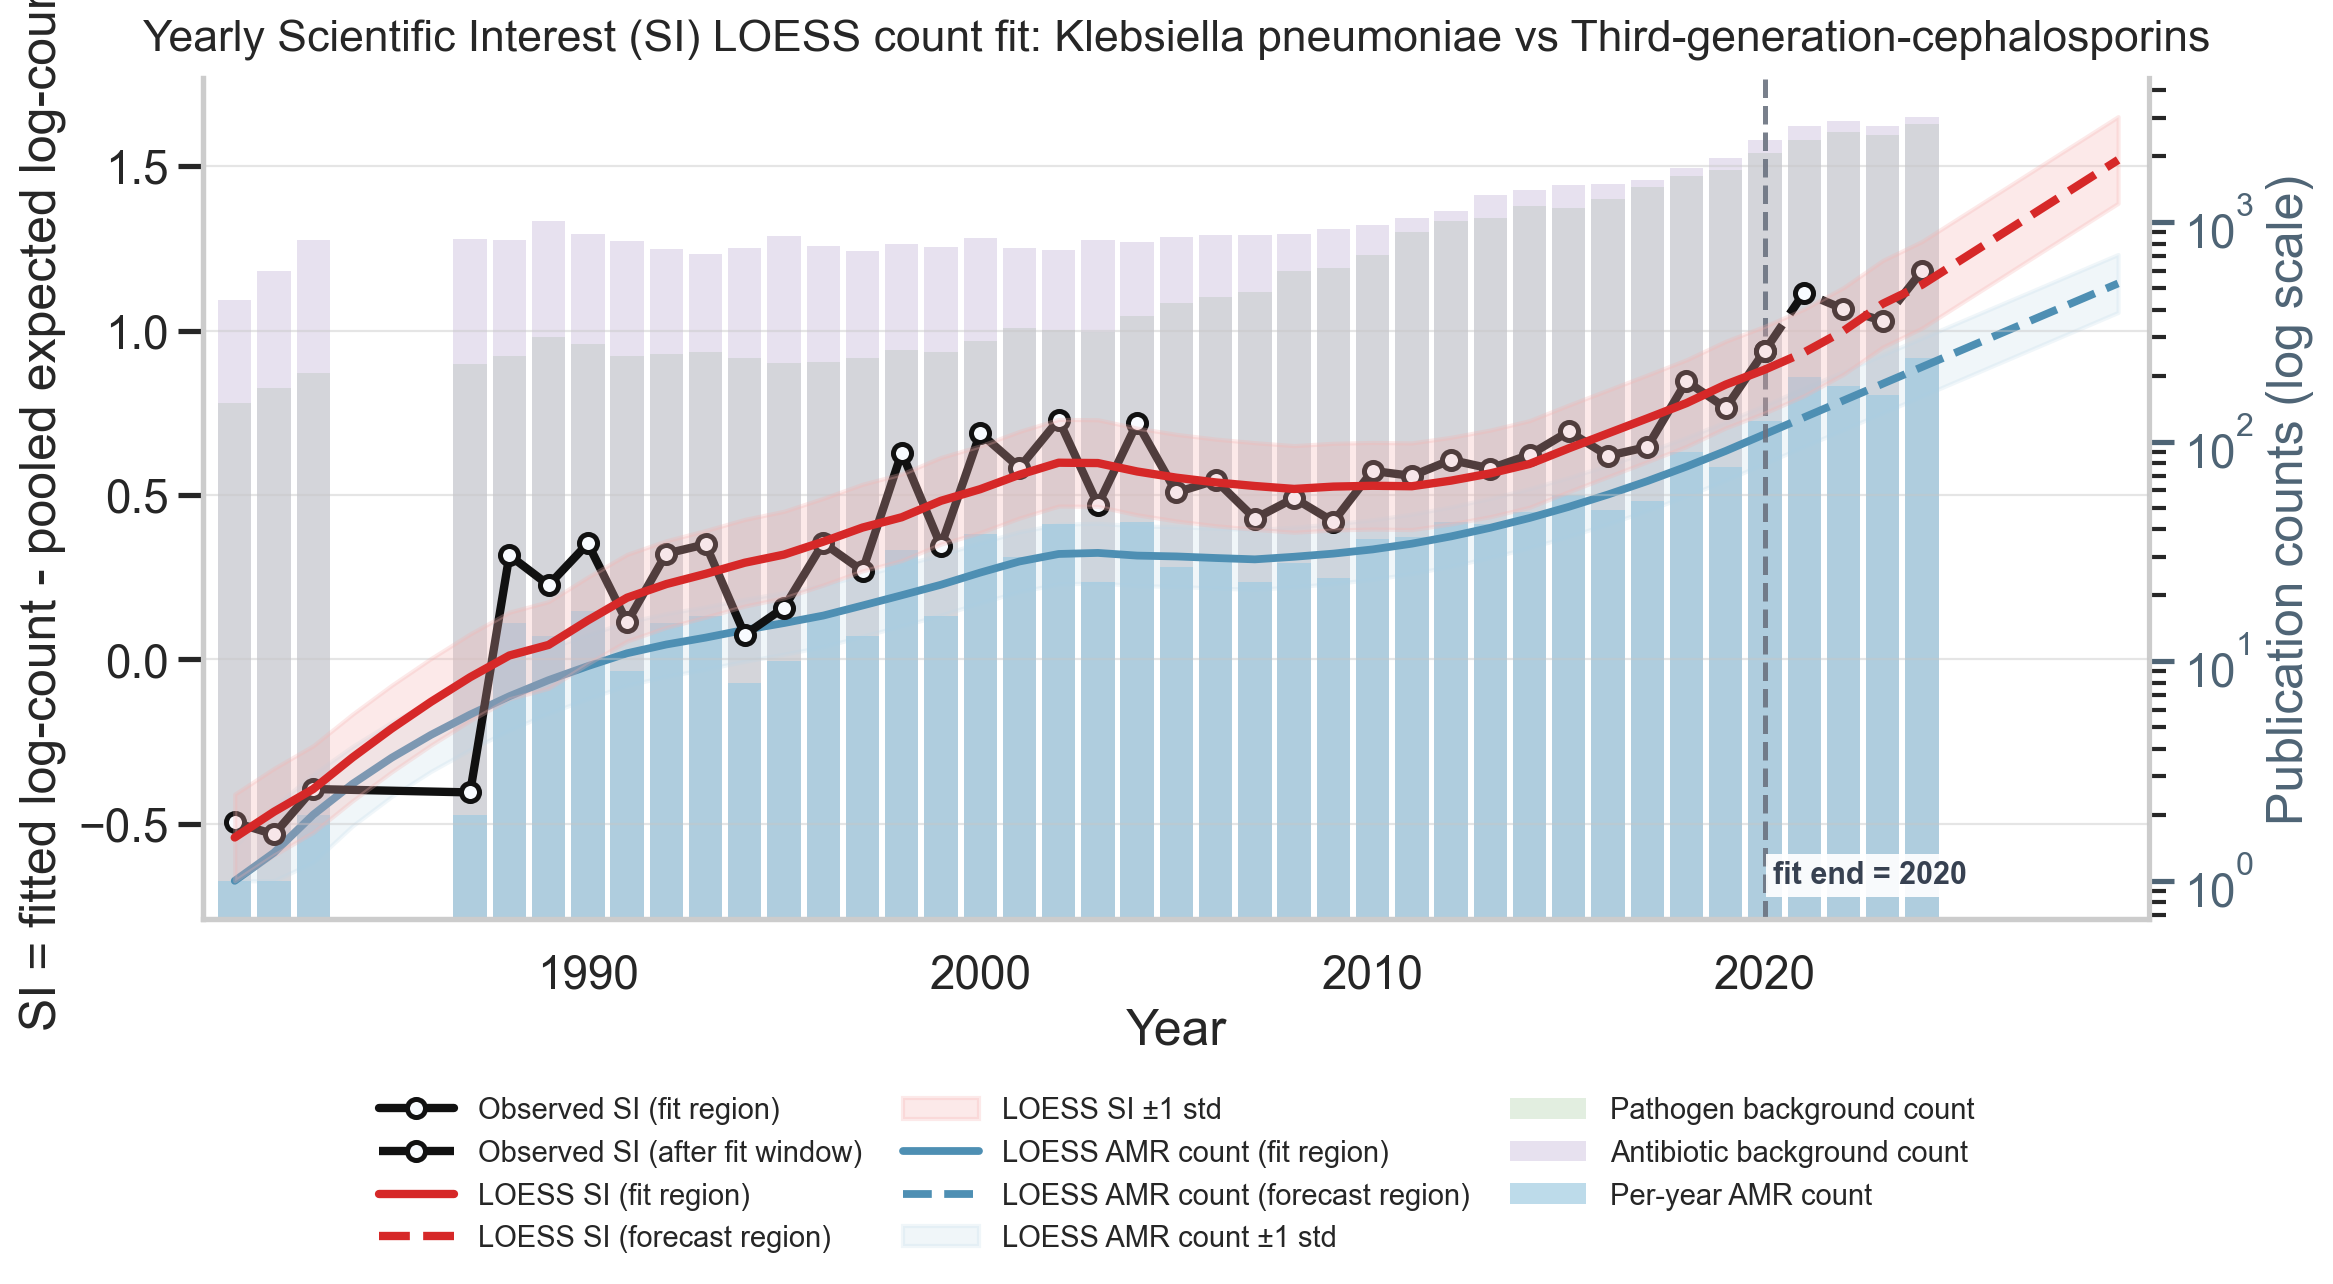

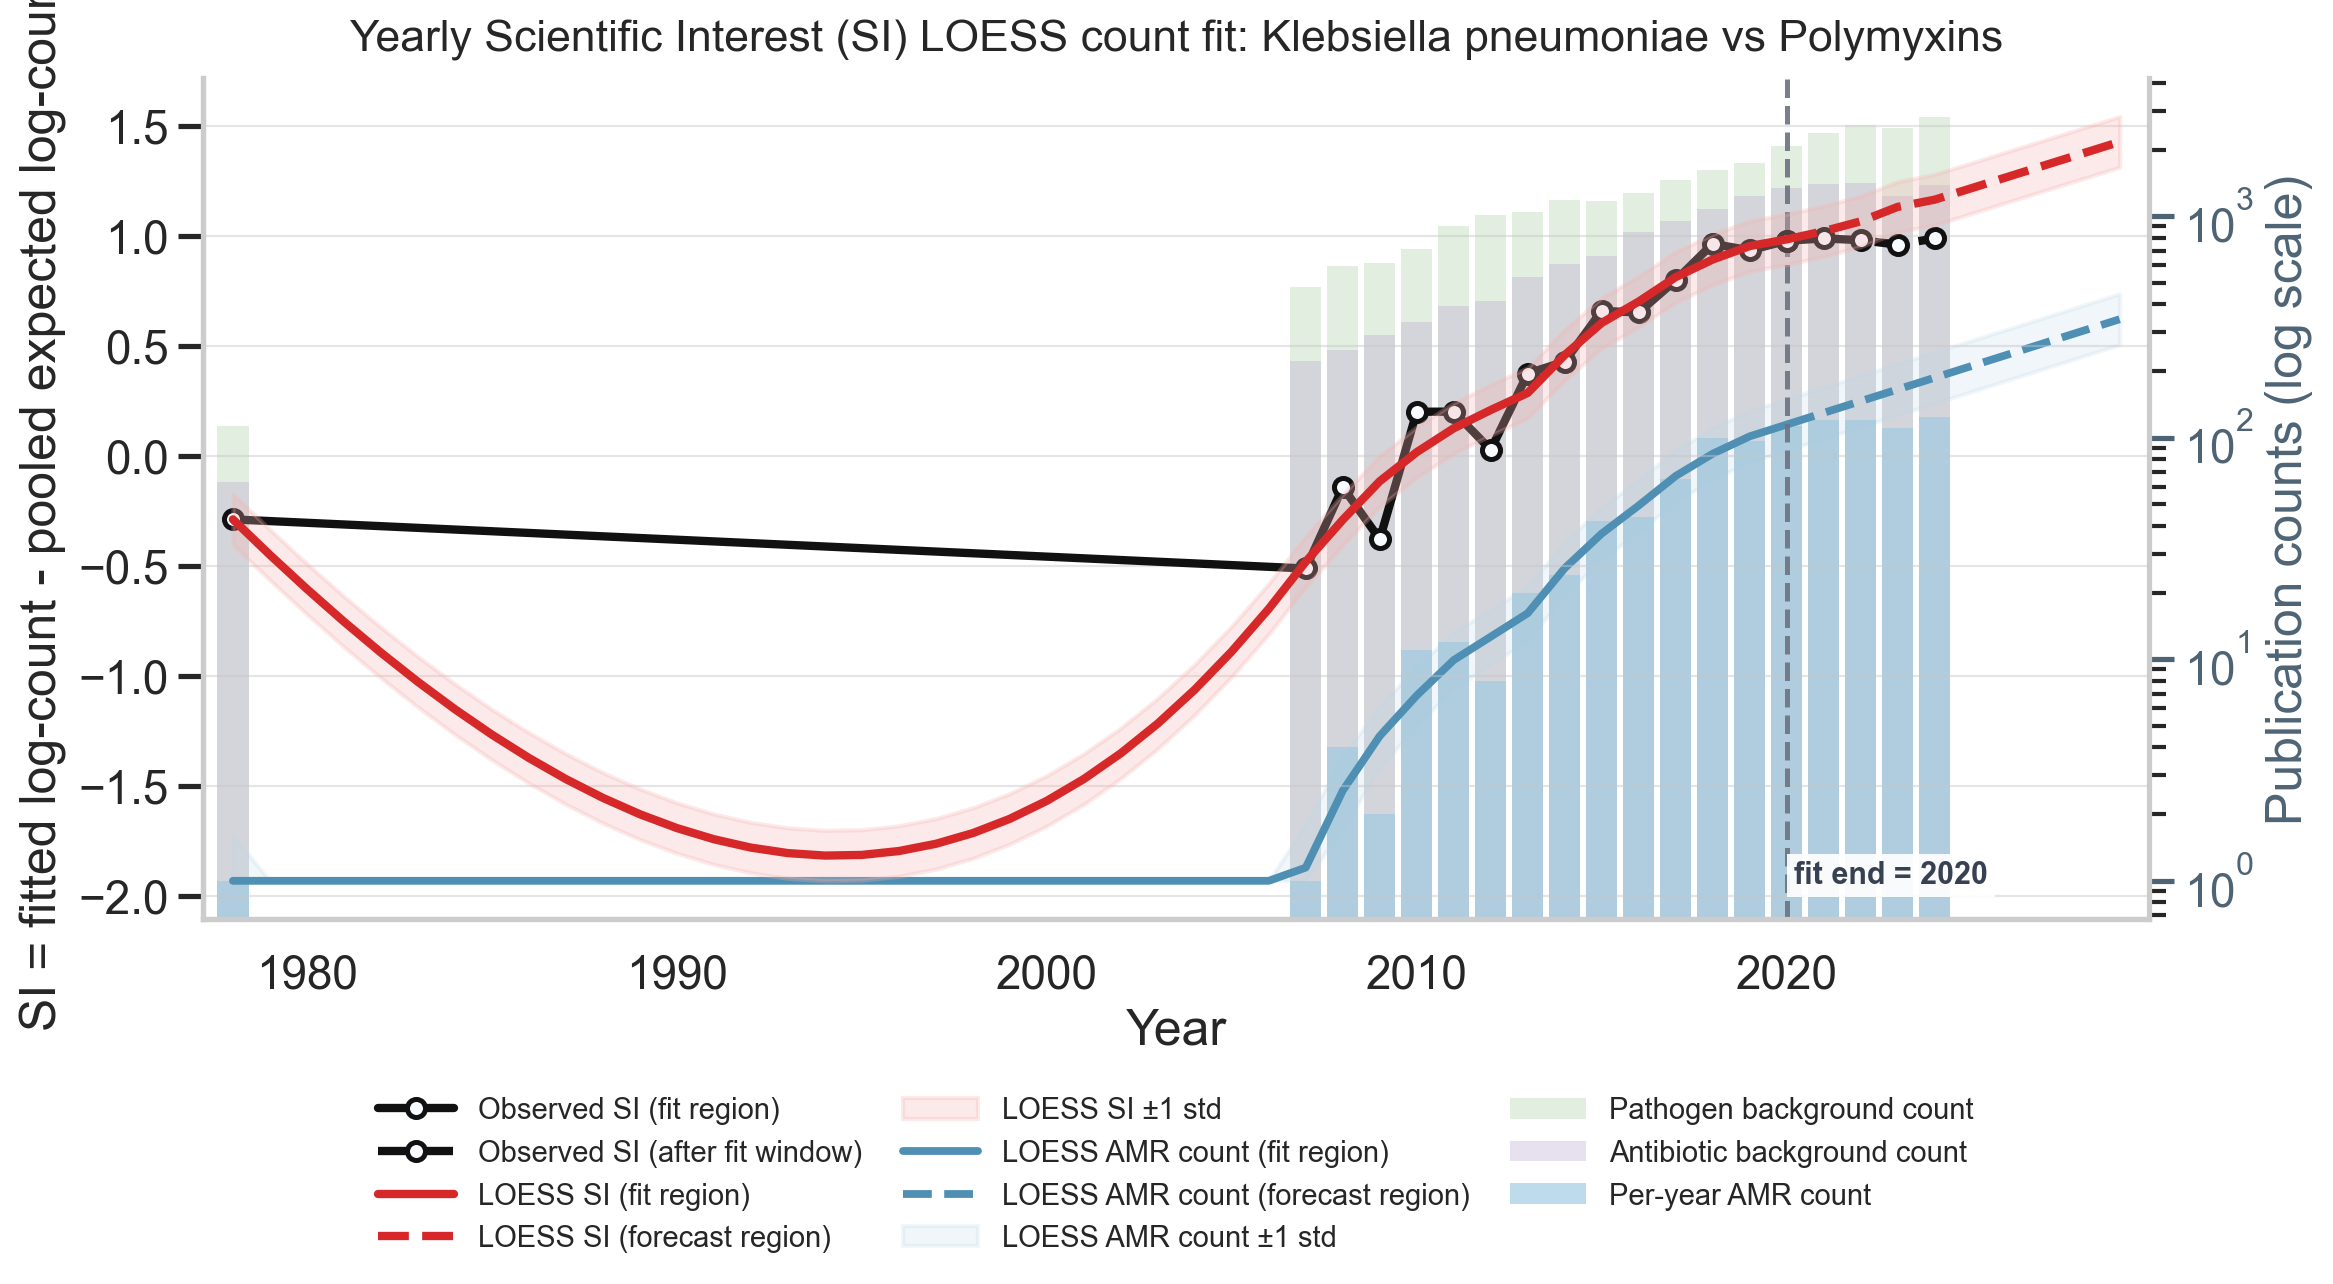

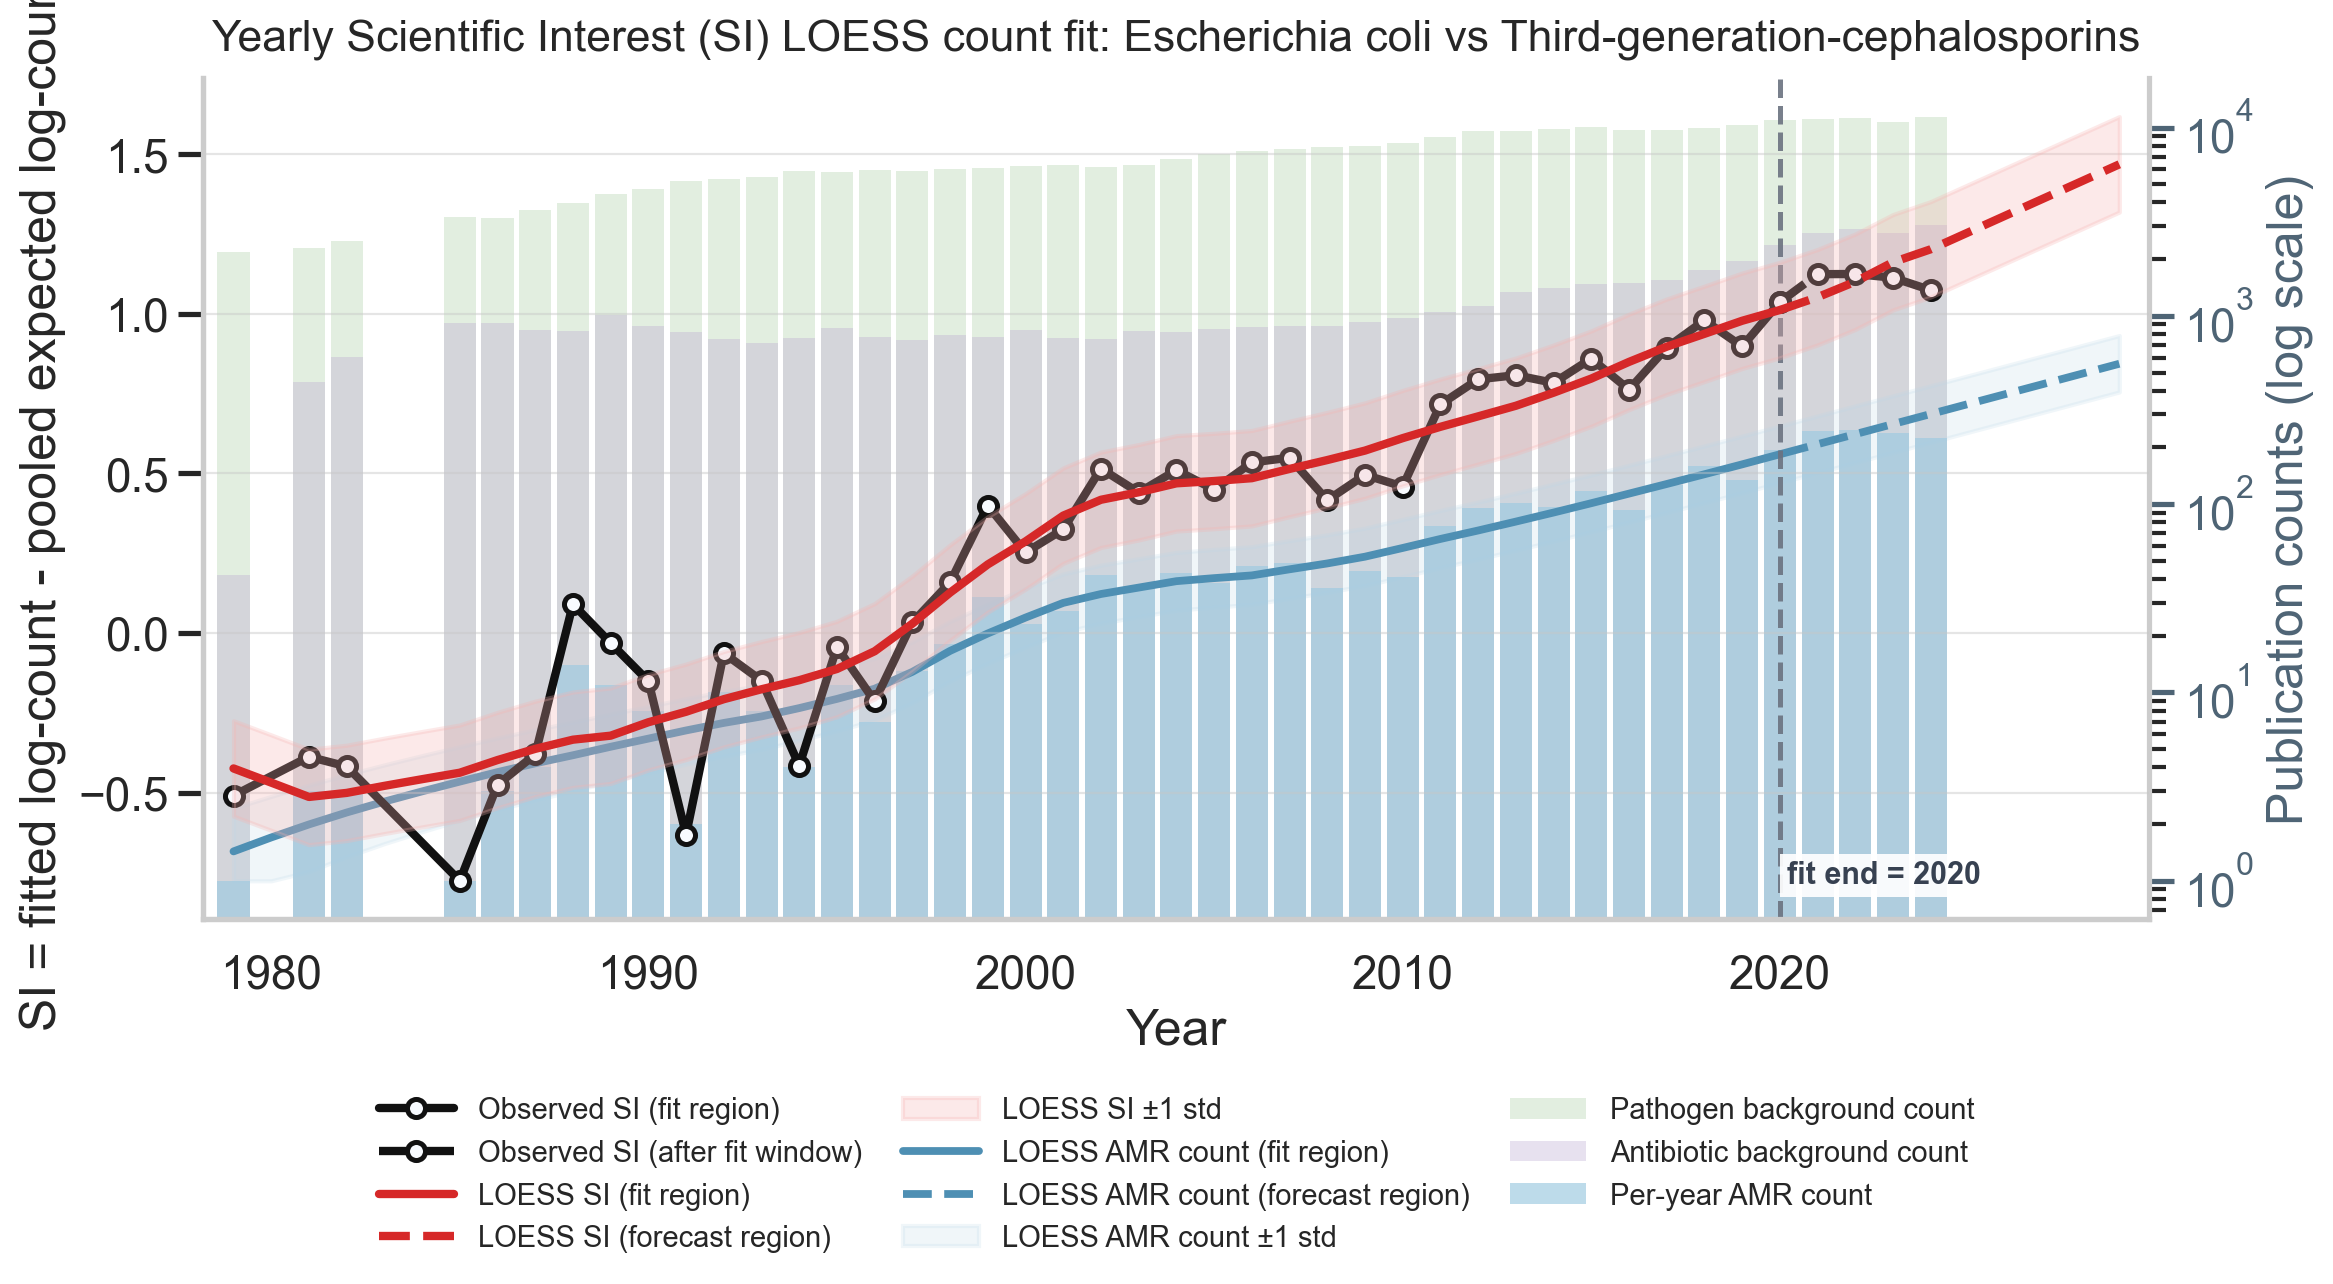

In [12]:
n_pareto_shells = 3
pareto_df = display_si_amr_pareto_front(si_df, n_pareto_shells=n_pareto_shells)
pareto_plot_results = plot_yearly_si_prediction_for_pareto_pairs(
    si_df,
    pareto_df,
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_additional_years=RANK_NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
    n_pareto_shells=n_pareto_shells,
    save_dir=str(PARETO_PNG_DIR),
)


## Rank future SI shifts for pathogen-group pairs


In [13]:
%%time

if RANK_OUTPUT_PATH.exists():
    print(f"Loading cached rank_df from {RANK_OUTPUT_PATH}")
    rank_df = pd.read_parquet(RANK_OUTPUT_PATH)
else:
    rank_df = rank_yearly_pairs_by_future_si_shift(
        si_df,
        fit_start_year=RANK_FIT_START_YEAR,
        fit_end_year=RANK_FIT_END_YEAR,
        num_future_years=RANK_NUM_FUTURE_YEARS,
        save_path=str(RANK_OUTPUT_PATH),
        verbose=True,
    )


Loading cached rank_df from /Users/fabriziocosta/Resilio Sync/Sync/Projects/Pathogen Atlas/Antimicrobial Resistance/archive/legacy_assets/si_yearly_rank_shift_class_fit_1970_2020_ref_2020_future_2025.parquet
CPU times: user 15.2 ms, sys: 10.5 ms, total: 25.7 ms
Wall time: 8.51 ms


In [14]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

rank_df = pd.read_parquet(RANK_OUTPUT_PATH)

interesting_df = select_interesting_yearly_rank_cases(
    rank_df,
    min_current_predicted_count=10,
    min_si_change=0.1,
    min_post_fit_observed_years=1,
    max_post_fit_si_abs_pct_error_mean=20,
    fallback_top_n=0,
)

minimal_df = interesting_df[
    [
        "pathogen",
        "antibiotic",
        "interest_score",
        "si_change",
        "current_predicted_count",
        "future_predicted_count",
        "post_fit_si_abs_pct_error_mean",
    ]
].copy()

minimal_df


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,post_fit_si_abs_pct_error_mean
0,Escherichia coli,Penicillins,0.462174,0.186698,272.895788,430.312039,2.946124
1,Klebsiella pneumoniae,Third-generation-cephalosporins,0.417340,0.220603,108.401275,201.115677,10.311277
2,Escherichia coli,Third-generation-cephalosporins,0.389039,0.171419,184.073672,288.267798,4.005384
3,Klebsiella pneumoniae,Polymyxins,0.320697,0.165005,114.638591,180.114714,8.191828
4,Escherichia coli,Trimethoprim-derivatives,0.314134,0.168626,105.311917,159.399150,9.765851
5,Enterococcus faecium,Glycopeptides,0.277245,0.152094,113.456863,167.984802,10.768518
6,Klebsiella pneumoniae,Penicillins,0.262845,0.164975,52.682641,83.870143,12.566551
7,Staphylococcus aureus,Second-generation-cephalosporins,0.258767,0.156947,43.450568,66.106944,6.189065
8,Escherichia coli,Beta-lactam/beta-lactamase-inhibitor,0.243514,0.144614,45.597973,66.407787,4.890689
9,Escherichia coli,Sulfonamide-trimethoprim-combinations,0.238635,0.123640,87.261616,119.704691,4.210363


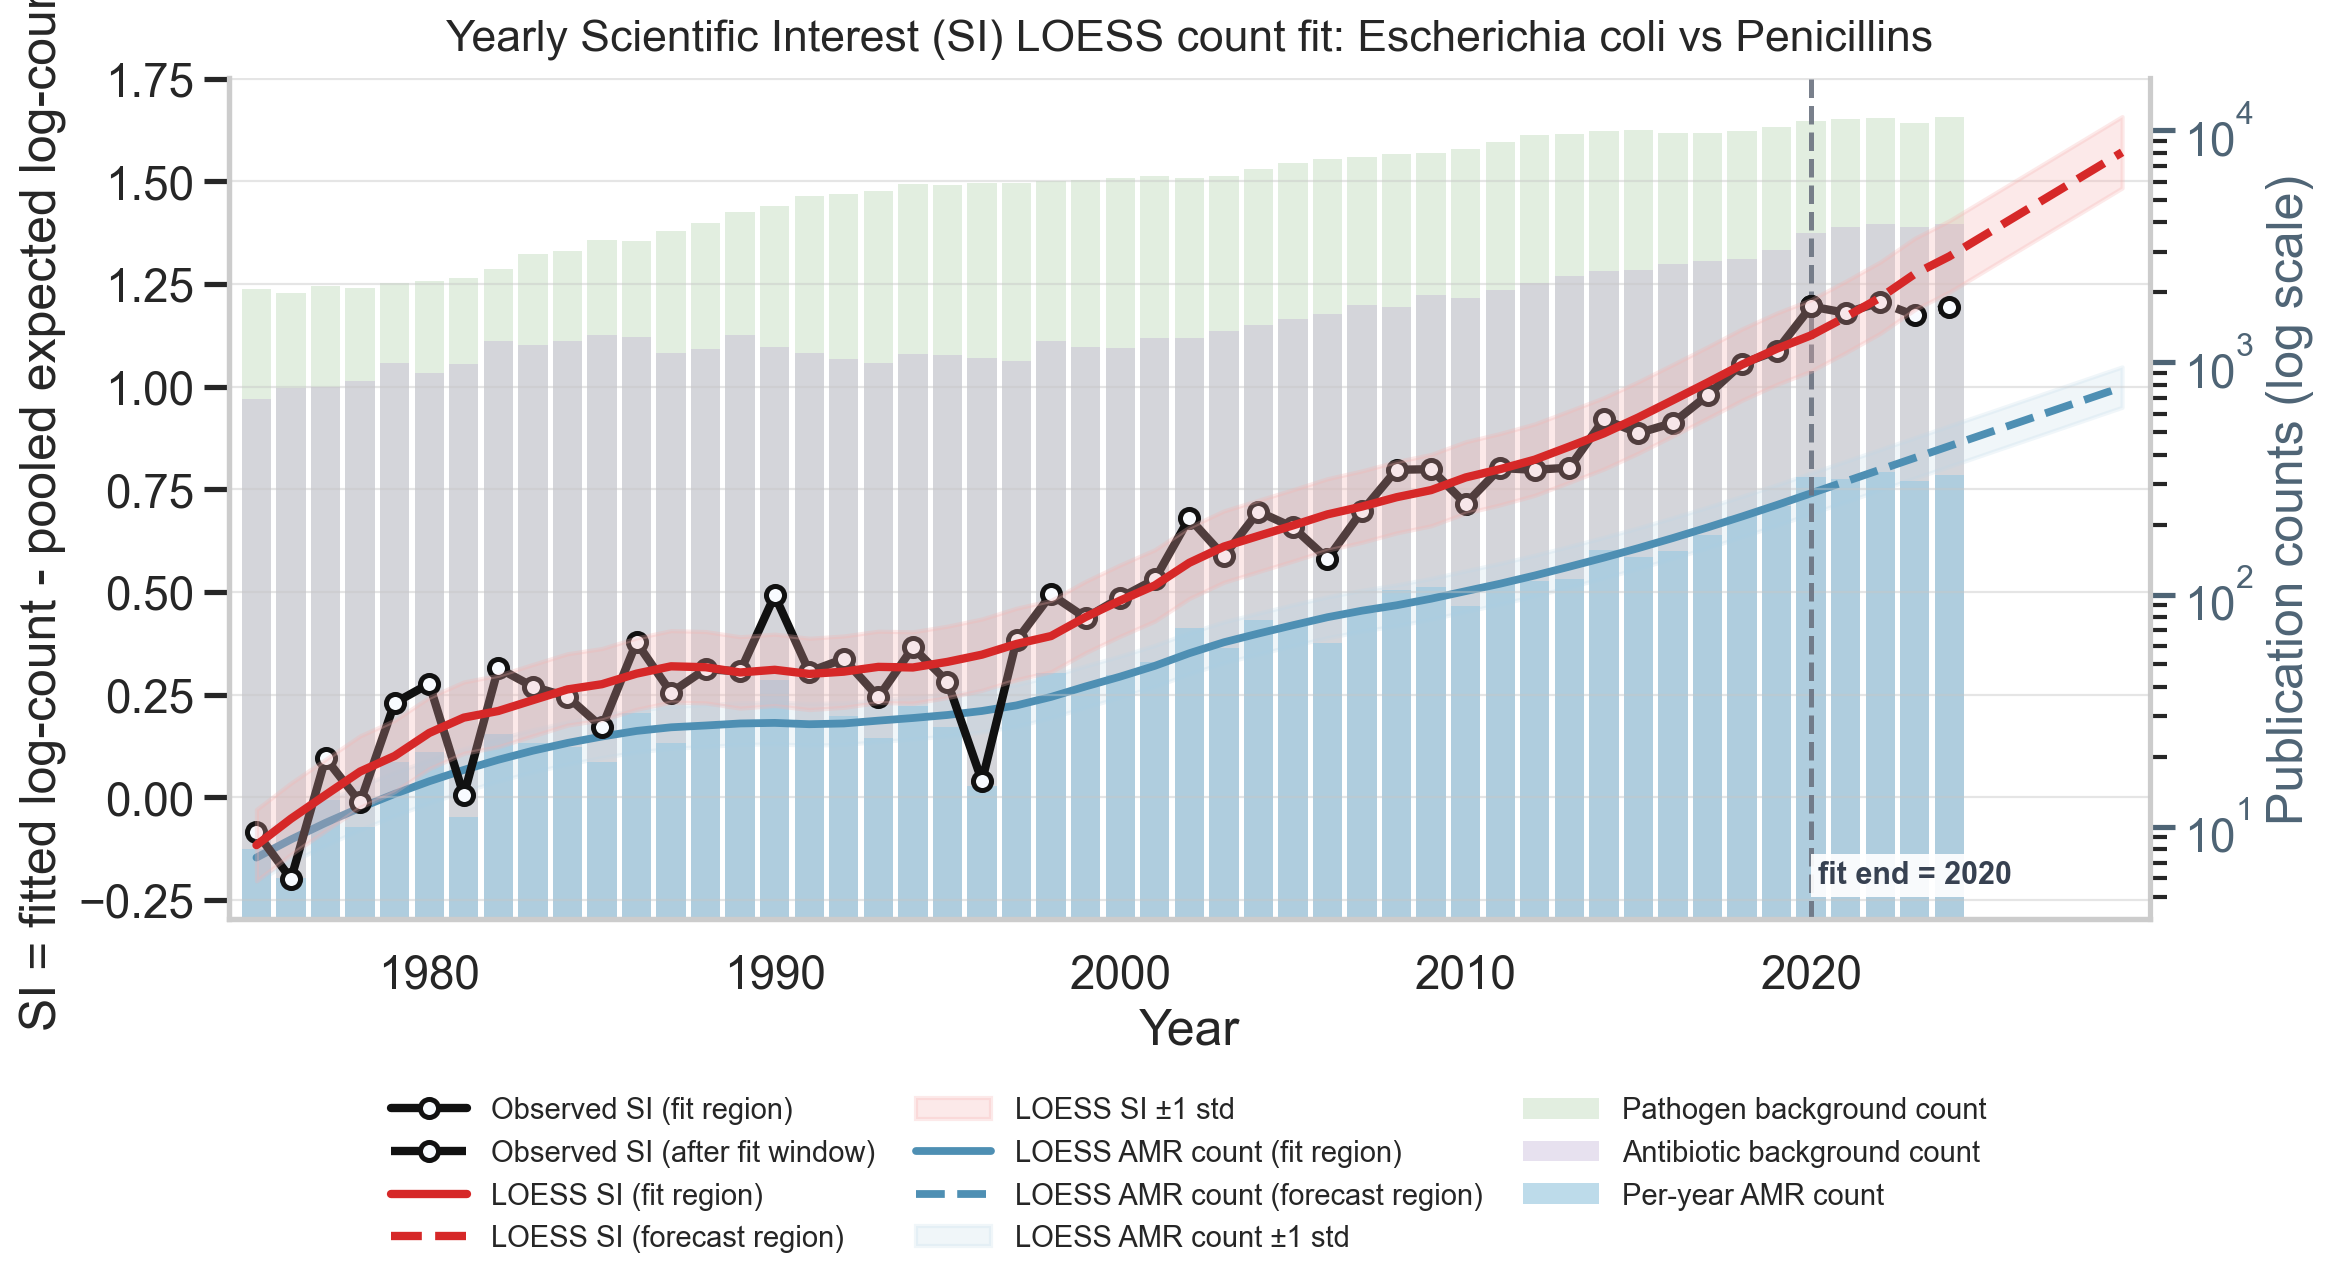

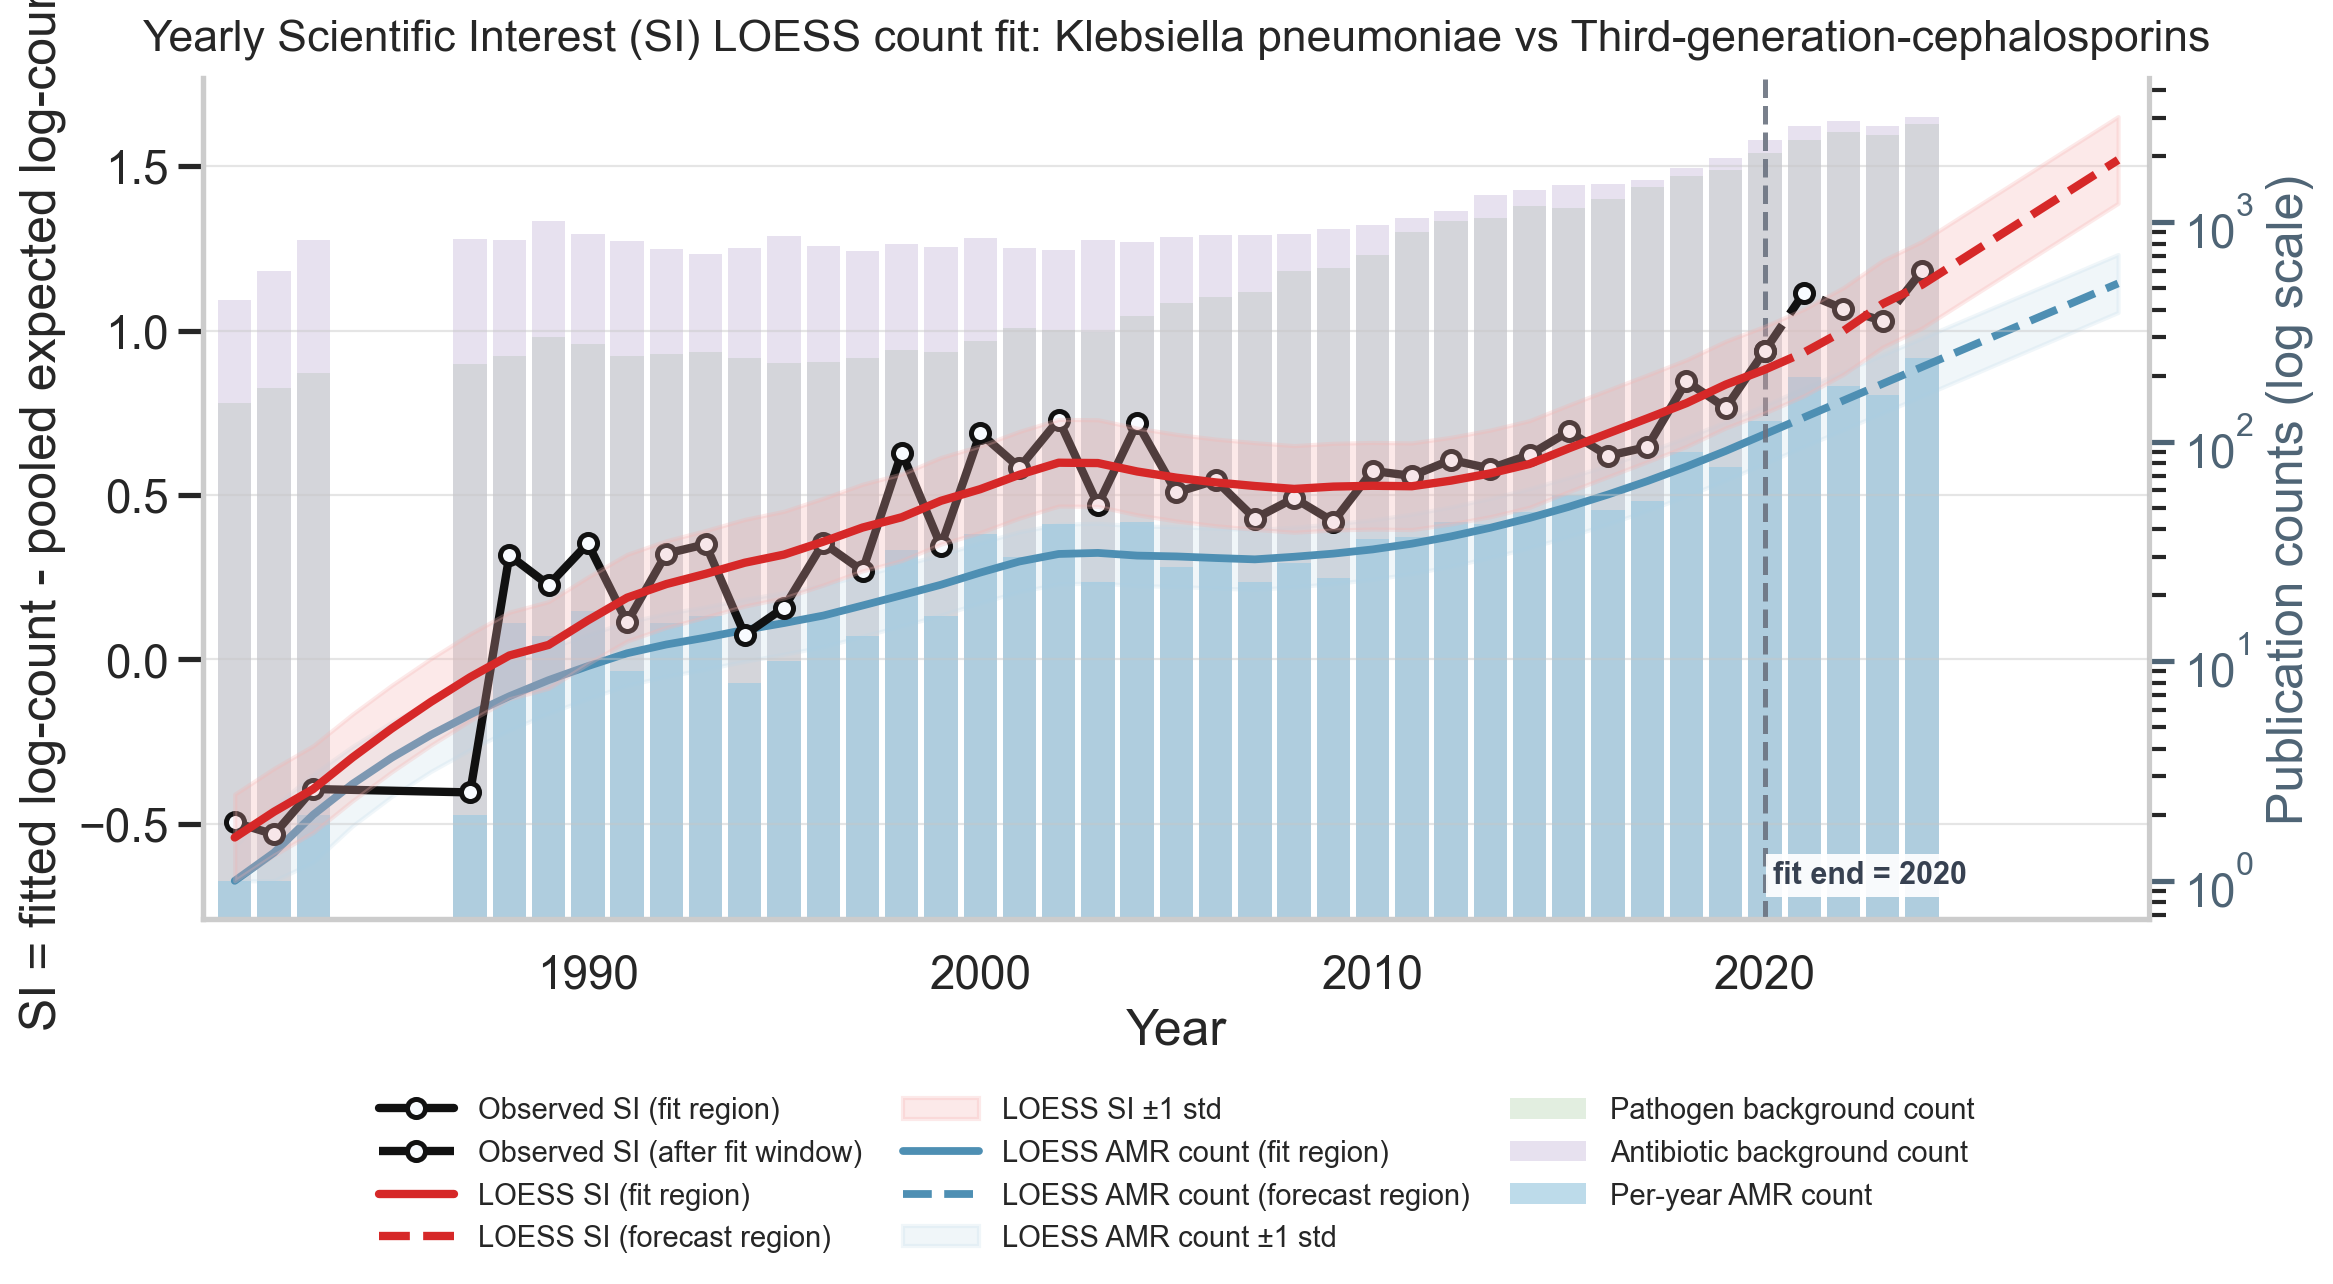

In [ ]:
INTERESTING_PNG_DIR.mkdir(parents=True, exist_ok=True)

for pathogen, antibiotic_group in minimal_df[["pathogen", "antibiotic"]].values:
    result = plot_yearly_si_pair(
        si_df=si_df,
        pathogen=pathogen,
        antibiotic=antibiotic_group,
        fit_start_year=RANK_FIT_START_YEAR,
        fit_end_year=RANK_FIT_END_YEAR,
        num_additional_years=RANK_NUM_FUTURE_YEARS,
        loess_frac=0.6,
        loess_degree=2,
        tail_damping_years=None,
    )

    pathogen_slug = str(pathogen).replace("/", "_").replace(" ", "_")
    group_slug = str(antibiotic_group).replace("/", "_").replace(" ", "_")
    out_path = INTERESTING_PNG_DIR / f"{pathogen_slug}__{group_slug}.png"
    result["figure"].savefig(out_path, dpi=200, bbox_inches="tight")

print(f"Saved {len(minimal_df):,} interesting-case PNGs to {INTERESTING_PNG_DIR}")


---

## Predicted AMR count vs scientific interest

Each label shows the pathogen and antibiotic on separate lines. The arrow starts at the latest predicted AMR count and SI, and points to the prediction `RANK_NUM_FUTURE_YEARS` years ahead.

In [ ]:
RANK_SAMPLE_SIZE = 5000
RANK_SAMPLE_RANDOM_STATE = None
PLOT_MIN_CURRENT_COUNT = 20
PLOT_MAX_COUNT = 1e4

plot_rank_df = rank_df.loc[
    rank_df["current_count"] >= PLOT_MIN_CURRENT_COUNT
].copy()
plot_rank_df["plot_current_predicted_count"] = plot_rank_df["current_count"].clip(
    upper=PLOT_MAX_COUNT
)
plot_rank_df["plot_future_predicted_count"] = plot_rank_df["future_predicted_count"].clip(
    upper=PLOT_MAX_COUNT
)
sample_n = min(RANK_SAMPLE_SIZE, len(plot_rank_df))
sample_rank_df = plot_rank_df.sample(sample_n, random_state=RANK_SAMPLE_RANDOM_STATE)
fig = plot_interactive_yearly_rank_shift(
    sample_rank_df,
    title=(
        f"Current count to future ({RANK_NUM_FUTURE_YEARS} years) predicted AMR count vs scientific interest"
    ),
)


In [ ]:
GLASS_pairs_df = pd.DataFrame(
    [
        {"pathogen": "Escherichia coli", "antibiotic": "Third-generation-cephalosporins"},
        {"pathogen": "Escherichia coli", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Escherichia coli", "antibiotic": "Carbapenems"},
        {"pathogen": "Klebsiella pneumoniae", "antibiotic": "Third-generation-cephalosporins"},
        {"pathogen": "Klebsiella pneumoniae", "antibiotic": "Carbapenems"},
        {"pathogen": "Klebsiella pneumoniae", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Acinetobacter baumannii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter bereziniae", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter calcoaceticus", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter haemolyticus", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter johnsonii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter junii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter lwoffii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter nosocomialis", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter pittii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter radioresistens", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter schindleri", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter seifertii", "antibiotic": "Carbapenems"},
        {"pathogen": "Acinetobacter ursingii", "antibiotic": "Carbapenems"},
        {"pathogen": "Salmonella enterica", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Shigella boydii", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Shigella dysenteriae", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Shigella flexneri", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Shigella sonnei", "antibiotic": "Fluoroquinolones"},
        {"pathogen": "Staphylococcus aureus", "antibiotic": "Meticillin"},
        {"pathogen": "Streptococcus pneumoniae", "antibiotic": "Penicillins"},
        {"pathogen": "Streptococcus pneumoniae", "antibiotic": "Macrolides"},
        {"pathogen": "Neisseria gonorrhoeae", "antibiotic": "Ciprofloxacin"},
        {"pathogen": "Neisseria gonorrhoeae", "antibiotic": "Azithromycin"},
        {"pathogen": "Neisseria gonorrhoeae", "antibiotic": "Ceftriaxone"},
    ]
)

glass_meta_cols = ["Antibiotic", "Class", "Simplified categories", "High level categories"]
glass_meta_df = antibiotics_df[glass_meta_cols].copy()
glass_meta_df = glass_meta_df.replace({"": np.nan})
for col in glass_meta_cols:
    glass_meta_df[col] = glass_meta_df[col].astype(str).str.strip()
glass_meta_df = glass_meta_df.replace({"nan": np.nan})

glass_lookup_sources = []
for source_col in ["Antibiotic", "Class", "Simplified categories", "High level categories"]:
    source_df = pd.DataFrame(
        {
            "antibiotic": glass_meta_df[source_col],
            "Class": glass_meta_df["Class"],
            "Simplified categories": glass_meta_df["Simplified categories"],
            "High level categories": glass_meta_df["High level categories"],
        }
    )
    source_df = source_df.dropna(subset=["antibiotic"]).drop_duplicates()
    source_df["matched_on"] = source_col
    glass_lookup_sources.append(source_df)

glass_lookup_df = pd.concat(glass_lookup_sources, ignore_index=True)
glass_lookup_df["match_priority"] = glass_lookup_df["matched_on"].map(
    {
        "Antibiotic": 0,
        "Class": 1,
        "Simplified categories": 2,
        "High level categories": 3,
    }
)
glass_lookup_df = glass_lookup_df.sort_values(["antibiotic", "match_priority"])
glass_lookup_df = glass_lookup_df.drop_duplicates(subset=["antibiotic"], keep="first")

GLASS_pairs_df = GLASS_pairs_df.merge(
    glass_lookup_df[["antibiotic", "Class", "Simplified categories", "High level categories", "matched_on"]],
    on="antibiotic",
    how="left",
)

display(GLASS_pairs_df)


,pathogen,antibiotic,Class,Simplified categories,High level categories,matched_on
0,Escherichia coli,Third-generation-cephalosporins,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Class
1,Escherichia coli,Fluoroquinolones,Fluoroquinolones,Qinolones/fluoroquinolones,Qinolones/fluoroquinolones,Class
2,Escherichia coli,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class
3,Klebsiella pneumoniae,Third-generation-cephalosporins,Third-generation-cephalosporins,Cephalosporins,Beta lactam and related,Class
4,Klebsiella pneumoniae,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class
5,Klebsiella pneumoniae,Fluoroquinolones,Fluoroquinolones,Qinolones/fluoroquinolones,Qinolones/fluoroquinolones,Class
6,Acinetobacter baumannii,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class
7,Acinetobacter bereziniae,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class
8,Acinetobacter calcoaceticus,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class
9,Acinetobacter haemolyticus,Carbapenems,Carbapenems,Penems/Carbapenems,Beta lactam and related,Class


In [ ]:
MAX_COUNT_ABS_PCT_ERROR_MEAN = 50
MIN_COUNT_ABS_PCT_ERROR_MEAN = 1
latest_count_shift_result = plot_interactive_latest_observed_count_vs_future_si_shift(
    rank_df,
    GLASS_pairs_df=GLASS_pairs_df,
    min_last_available_count=10,
    min_count_abs_pct_error_mean=MIN_COUNT_ABS_PCT_ERROR_MEAN,
    max_count_abs_pct_error_mean=MAX_COUNT_ABS_PCT_ERROR_MEAN,
    min_counts_background=20,
    min_abs_delta_si=0.05,
    min_si_delta=-0.2,
    display_name=True,
    show=False,
)

latest_count_shift_df = latest_count_shift_result["plot_df"]
avg_latest_year = latest_count_shift_df["latest_available_year"].mean()
avg_future_year = avg_latest_year + RANK_NUM_FUTURE_YEARS
latest_count_shift_result["figure"].update_layout(
    title=(
        f"Latest available AMR count vs SI change from smoothed SI at average latest year {avg_latest_year:.1f} "
        f"to average predicted year {avg_future_year:.1f} "
        f"(mean abs count error <= {MAX_COUNT_ABS_PCT_ERROR_MEAN:g}%)"
    )
)
latest_count_shift_result["figure"].show()

latest_count_shift_export_df = latest_count_shift_df[
    [
        "pathogen",
        "antibiotic",
        "latest_available_year",
        "future_year",
        "latest_available_predicted_count",
        "future_predicted_count",
        "latest_available_predicted_SI",
        "future_predicted_SI",
        "appears_in_GLASS",
        "post_fit_count_abs_pct_error_mean",
    ]
].rename(
    columns={
        "latest_available_year": "latest_year",
        "future_year": "future_year",
        "latest_available_predicted_count": "latest_count",
        "future_predicted_count": "future_predicted_count",
        "latest_available_predicted_SI": "latest_SI",
        "future_predicted_SI": "future_predicted_SI",
        "appears_in_GLASS": "appears_in_GLASS",
        "post_fit_count_abs_pct_error_mean": "error_pc",
    }
)
latest_count_shift_export_df["latest_count"] = latest_count_shift_export_df["latest_count"].round().astype(int)
latest_count_shift_export_df["future_predicted_count"] = latest_count_shift_export_df["future_predicted_count"].round().astype(int)
latest_count_shift_export_df = latest_count_shift_export_df.sort_values("latest_count", ascending=False)
latest_count_shift_xlsx_path = LEGACY_ASSETS_DIR / "predicted_SI.xlsx"
latest_count_shift_export_df.to_excel(latest_count_shift_xlsx_path, index=False)
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(latest_count_shift_export_df[latest_count_shift_export_df['appears_in_GLASS']=='yes'])
    display(latest_count_shift_export_df)


/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/archive/amr_legacy/scientific_interest.py:61: FutureWarning:

Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`



/mnt/data/sync/Projects/Pathogen Atlas/Antimicrobial Resistance/archive/legacy_notebooks/latest_observed_count_vs_future_si_shift.pdf


,pathogen,antibiotic,latest_year,future_year,latest_count,future_predicted_count,latest_SI,future_predicted_SI,appears_in_GLASS,error_pc
104,Escherichia coli,Third-generation-cephalosporins,2024.0,2029.0,252,288,1.125746,1.183719,yes,9.071586
88,Escherichia coli,Fluoroquinolones,2024.0,2029.0,192,200,0.984262,1.002355,yes,11.957801
111,Klebsiella pneumoniae,Third-generation-cephalosporins,2024.0,2029.0,168,201,1.025272,1.101966,yes,20.587562
91,Klebsiella pneumoniae,Carbapenems,2024.0,2029.0,123,131,0.979001,1.004095,yes,10.104377
68,Escherichia coli,Carbapenems,2024.0,2029.0,68,71,0.651848,0.667001,yes,11.910714
75,Salmonella enterica,Fluoroquinolones,2024.0,2029.0,60,62,0.722466,0.741026,yes,4.382944
66,Acinetobacter baumannii,Carbapenems,2024.0,2029.0,55,57,0.745229,0.756140,yes,14.513123
37,Klebsiella pneumoniae,Fluoroquinolones,2024.0,2029.0,49,51,0.473568,0.488720,yes,23.959504
57,Streptococcus pneumoniae,Macrolides,2024.0,2029.0,40,40,0.612823,0.614231,yes,7.241672


,pathogen,antibiotic,latest_year,future_year,latest_count,future_predicted_count,latest_SI,future_predicted_SI,appears_in_GLASS,error_pc
110,Escherichia coli,Penicillins,2024.0,2029.0,372,430,1.249039,1.311936,no,9.801619
104,Escherichia coli,Third-generation-cephalosporins,2024.0,2029.0,252,288,1.125746,1.183719,yes,9.071586
88,Escherichia coli,Fluoroquinolones,2024.0,2029.0,192,200,0.984262,1.002355,yes,11.957801
111,Klebsiella pneumoniae,Third-generation-cephalosporins,2024.0,2029.0,168,201,1.025272,1.101966,yes,20.587562
105,Klebsiella pneumoniae,Polymyxins,2024.0,2029.0,157,180,1.089183,1.148455,no,16.939104
97,Escherichia coli,Tetracyclines,2024.0,2029.0,155,168,0.919689,0.954959,no,17.373141
109,Enterococcus faecium,Glycopeptides,2024.0,2029.0,153,168,1.218918,1.259683,no,26.570647
103,Escherichia coli,Trimethoprim-derivatives,2024.0,2029.0,140,159,1.015445,1.072415,no,20.508073
77,Staphylococcus aureus,Penicillins,2024.0,2029.0,134,131,0.850151,0.840837,no,24.730778
79,Escherichia coli,Aminoglycosides,2024.0,2029.0,127,129,0.822177,0.831366,no,15.075917


Example plot for Escherichia coli vs Penicillins (Class)


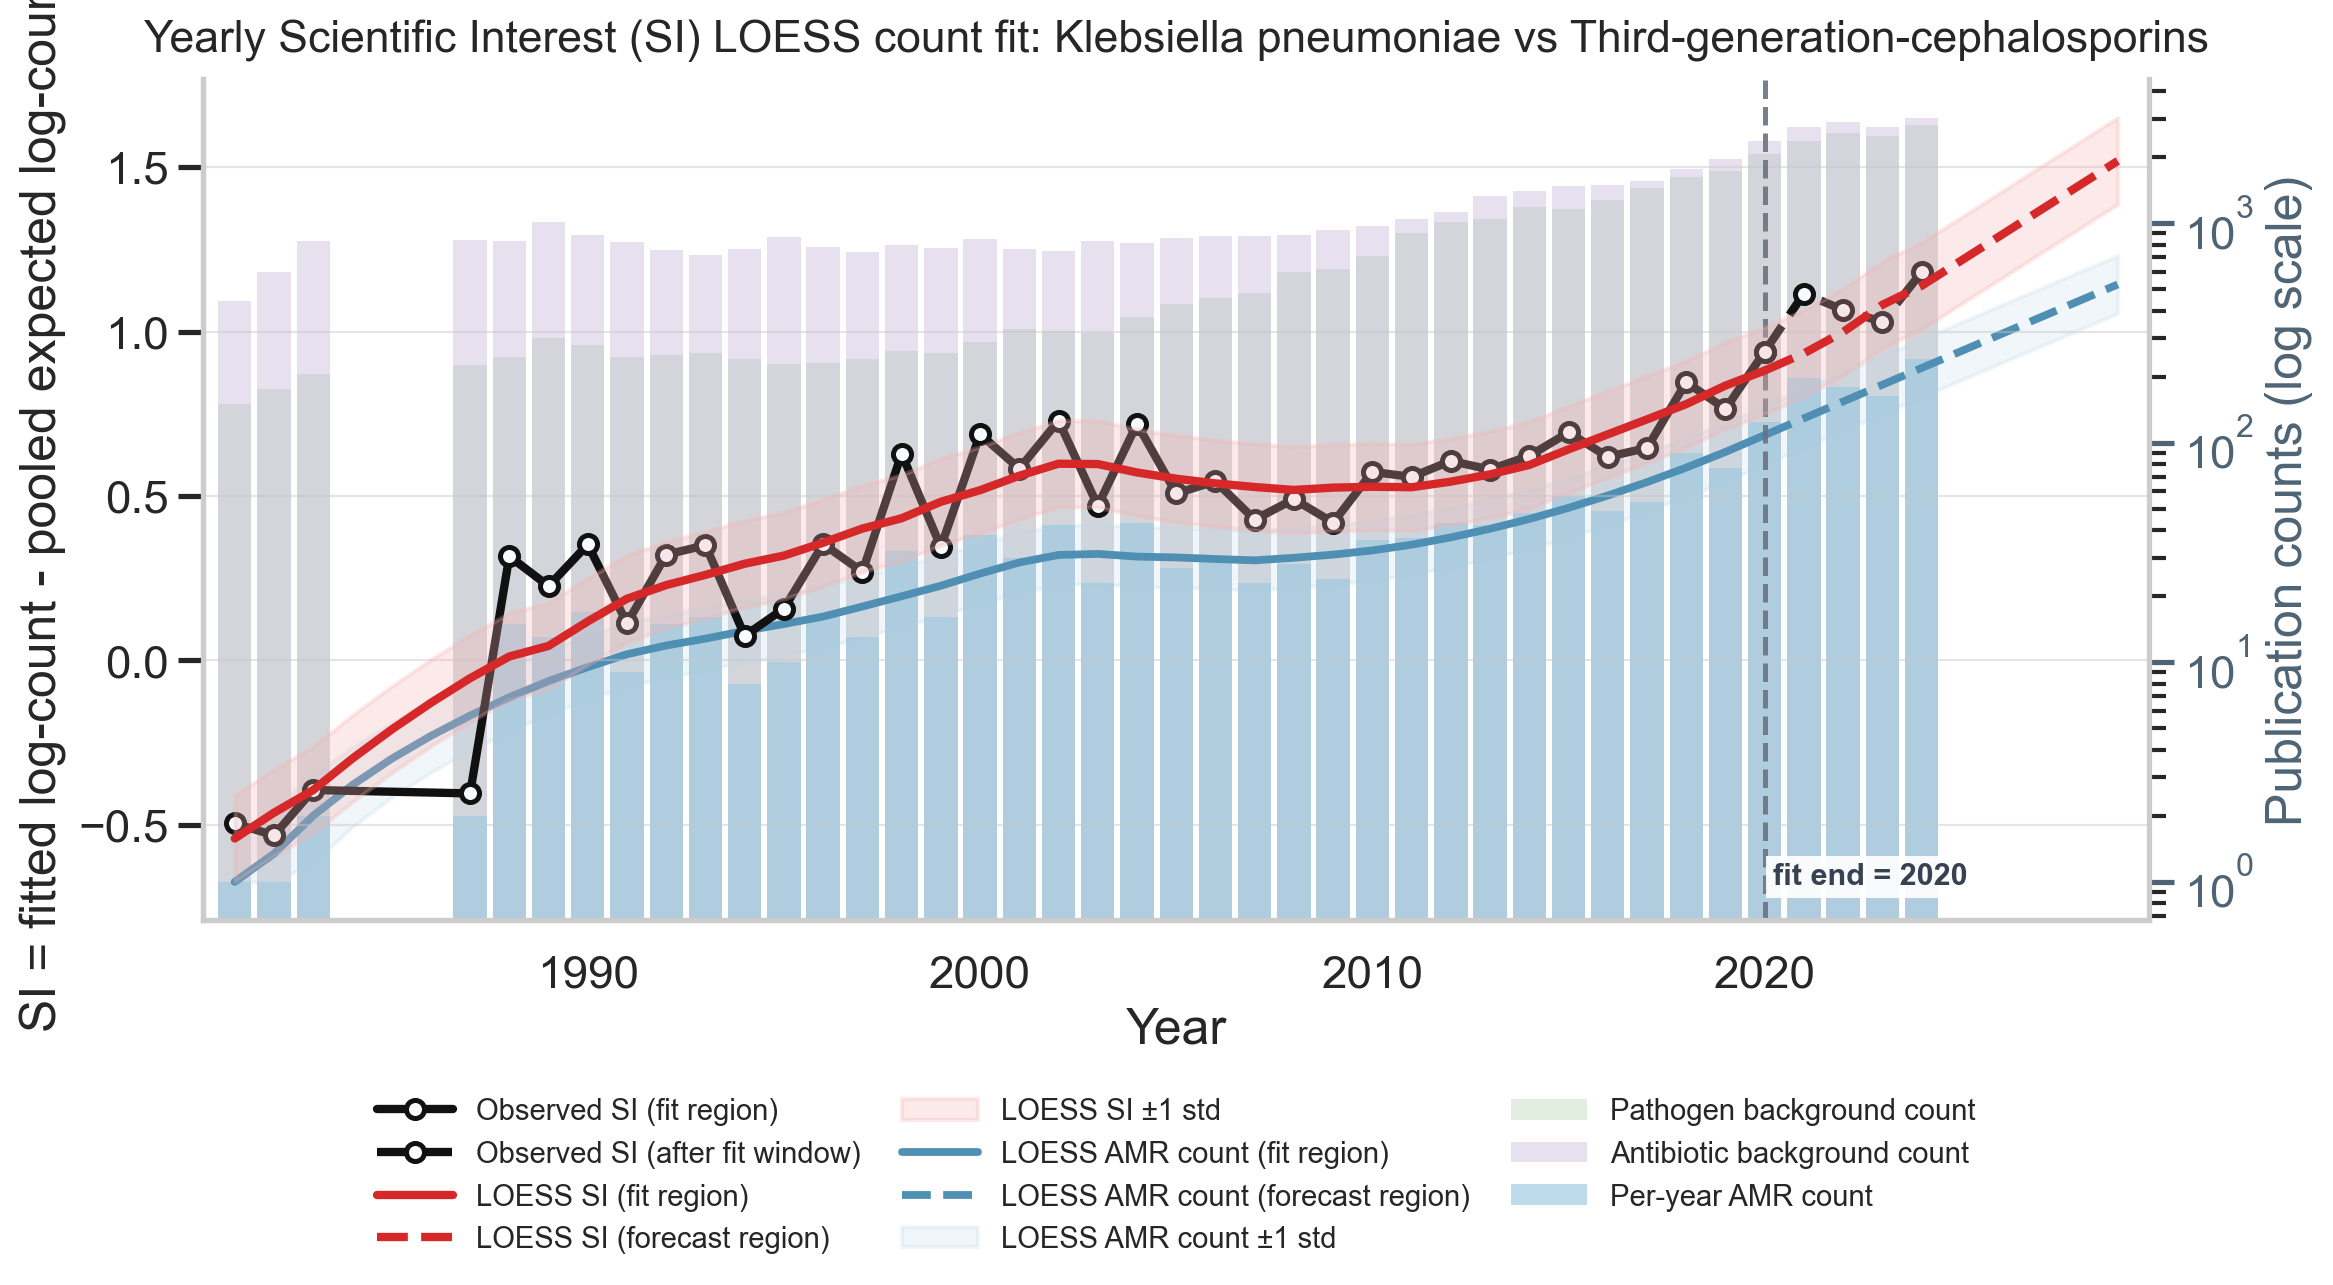

,year,observed_count,predicted_count,diff,pct_error
0,1981,1,1,0,0.000000
1,1982,1,1,0,0.000000
2,1983,2,2,0,0.000000
3,1987,2,6,-4,-200.000000
4,1988,15,7,8,53.333333
5,1989,13,8,5,38.461538
6,1990,17,10,7,41.176471
7,1991,9,11,-2,-22.222222
8,1992,15,12,3,20.000000
9,1993,16,13,3,18.750000


In [ ]:
if 'latest_count_shift_export_df' in globals() and not latest_count_shift_export_df.empty:
    example_row = latest_count_shift_export_df.iloc[0]
    example_pathogen = example_row['pathogen']
    example_group = example_row['antibiotic']
else:
    example_row = si_df[['pathogen', 'antibiotic']].drop_duplicates().sample(1, random_state=None).iloc[0]
    example_pathogen = example_row['pathogen']
    example_group = example_row['antibiotic']

print(f"Example plot for {example_pathogen} vs {example_group} ({ANTIBIOTIC_GROUP_COLUMN})")
result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen='Klebsiella pneumoniae',
    antibiotic='Third-generation-cephalosporins',
    fit_start_year=RANK_FIT_START_YEAR,
    fit_end_year=RANK_FIT_END_YEAR,
    num_additional_years=RANK_NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=2,
    tail_damping_years=None,
)
display(result['comparison_df'])

In [ ]:
latest_count_shift_export_df[latest_count_shift_export_df['appears_in_GLASS']=='yes']

,pathogen,antibiotic,latest_year,future_year,latest_count,future_predicted_count,latest_SI,future_predicted_SI,appears_in_GLASS,error_pc
104,Escherichia coli,Third-generation-cephalosporins,2024.0,2029.0,252,288,1.125746,1.183719,yes,9.071586
88,Escherichia coli,Fluoroquinolones,2024.0,2029.0,192,200,0.984262,1.002355,yes,11.957801
111,Klebsiella pneumoniae,Third-generation-cephalosporins,2024.0,2029.0,168,201,1.025272,1.101966,yes,20.587562
91,Klebsiella pneumoniae,Carbapenems,2024.0,2029.0,123,131,0.979001,1.004095,yes,10.104377
68,Escherichia coli,Carbapenems,2024.0,2029.0,68,71,0.651848,0.667001,yes,11.910714
75,Salmonella enterica,Fluoroquinolones,2024.0,2029.0,60,62,0.722466,0.741026,yes,4.382944
66,Acinetobacter baumannii,Carbapenems,2024.0,2029.0,55,57,0.745229,0.756140,yes,14.513123
37,Klebsiella pneumoniae,Fluoroquinolones,2024.0,2029.0,49,51,0.473568,0.488720,yes,23.959504
57,Streptococcus pneumoniae,Macrolides,2024.0,2029.0,40,40,0.612823,0.614231,yes,7.241672


In [ ]:
latest_count_shift_export_df["pathogen"].dropna().drop_duplicates()

110                Escherichia coli
111           Klebsiella pneumoniae
109            Enterococcus faecium
77            Staphylococcus aureus
96              Helicobacter pylori
85           Pseudomonas aeruginosa
75              Salmonella enterica
66          Acinetobacter baumannii
106            Campylobacter jejuni
74            Enterococcus faecalis
65            Neisseria gonorrhoeae
57         Streptococcus pneumoniae
15       Mycobacterium tuberculosis
102        Streptococcus agalactiae
89          Mycobacterium abscessus
83               Campylobacter coli
20           Haemophilus influenzae
116            Enterobacter cloacae
39        Mycoplasmoides genitalium
14       Staphylococcus epidermidis
87           Listeria monocytogenes
33     Stenotrophomonas maltophilia
19           Streptococcus pyogenes
72                Proteus mirabilis
Name: pathogen, dtype: object

In [ ]:
latest_count_shift_export_df["antibiotic"].dropna().drop_duplicates()

110                                              Penicillins
104                          Third-generation-cephalosporins
88                                          Fluoroquinolones
105                                               Polymyxins
97                                             Tetracyclines
109                                            Glycopeptides
103                                 Trimethoprim-derivatives
79                                           Aminoglycosides
91                                               Carbapenems
96                                                Macrolides
98                     Sulfonamide-trimethoprim-combinations
78                                                Imidazoles
94                      Beta-lactam/beta-lactamase-inhibitor
43                                              Lincosamides
100                         Second-generation-cephalosporins
117                                              Phosphonics
108                     